# Prediction intervals for TGLF flux surrogates

An ensemble of five small neural networks predicts, for each plasma scenario in the `scan_db` table, three TGLF fluxes **together with a 90% prediction interval**: the ion heat flux $Q_i$, the electron heat flux $Q_e$ and the electron particle flux $\Gamma_e$.
Each network outputs the 5th, 50th and 95th percentile of every flux (quantile regression with the pinball loss), and the heat fluxes are modelled in log space.
The notebook then checks the intervals (accuracy and coverage) and studies what makes them wide or narrow.

**Contents**

1. Setup
2. Data: loading, splitting and preprocessing
3. Model: quantile network ensemble
4. Training
5. Predictions and calibration (Table 1, Figures 2 and 3)
6. What drives the width of the interval? (Figures 4 to 8)
7. Out-of-range inputs (Table 3, Figures 9 and 10, Table 4)
8. DIII-D reference case: input uncertainty (Tables 5 to 9, Figures 11 to 15)

**Conventions**

- Fluxes are in gyro-Bohm (GB) units.
- The *validation* and *test* sets are both held out from training. Every analysis figure is drawn for both: the **a** version is the validation set and the **b** version is the test set.
- "Band" and "interval" both mean the 5th to 95th percentile interval of the prediction.

## 1. Setup

Imports, plotting style and the constants shared by every section.

In [120]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [121]:
# plotting style, shared by every figure
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 8, "figure.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})

# the three targets, in the column order used everywhere (see step 2.1)
TARGET_KEYS = ["Q_i", "Q_e", "Gamma_e"]
TARGET_NAMES = ["Ion heat flux Q_i", "Electron heat flux Q_e", "Electron particle flux Gamma_e"]
TARGET_COLORS = ["tab:blue", "tab:orange", "tab:green"]
TARGET_MARKERS = ["o", "s", "^"]
LOG_FLUX_AXIS = [True, True, False]    # heat fluxes are positive and span orders of magnitude; the particle flux can be zero or negative

# analysis settings
N_FLUX_BINS = 50       # equal-width log10 flux bins for the training-data analysis (Figure 6)
MIN_CASES_PER_BIN = 3  # bins with fewer evaluation cases than this are not shown
N_INPUT_BINS = 10      # equal-count bins of each input for Figure 7

# figure titles: "Figure 2a. <text> (validation set)"; a = validation set, b = test set
SPLIT_LETTER = {"validation": "a", "test": "b"}

def fig_title(number, text, split=None, note=None):
    if split is None:
        return f"Figure {number}. {text}"
    return f"Figure {number}{SPLIT_LETTER[split]}. {text} ({split} set" + (f"; {note})" if note else ")")

## 2. Data: loading, splitting and preprocessing

The 5,000 scan runs are read from `data/scan_db_table.csv` (one row per run, every TGLF input and the six output fluxes).
Preprocessing follows `scandb_tglf_prediction_training.ipynb`; every statistic (correlations, variances, scalers) comes from the training set only.

1. Split the rows 70 / 15 / 15 into training, validation and test sets.
2. Drop all six output fluxes from the inputs and keep three as targets: $Q_i$ (`energy_flux_2`), $Q_e$ (`energy_flux_1`) and $\Gamma_e$ (`particle_flux_1`).
3. Drop the redundant ion-species label (`MASS_2` already encodes it) and encode what remains.
4. Drop invalid rows (non-finite values or a heat flux $\le 0$), highly correlated features (|r| > 0.9) and low-variance features.
5. Standardize the inputs.
6. Take the natural log of the two heat fluxes; $\Gamma_e$ can be negative and stays as it is. The model is trained on these log targets only.

In [122]:
# step 1: load the scan_db data and find the flux columns

df = pd.read_csv("data/scan_db_table.csv")

FLUX_PREFIXES = ("particle_flux_", "energy_flux_", "momentum_flux_")
numeric_df = df.select_dtypes("number")
y_variables = [c for c in numeric_df.columns if c.startswith(FLUX_PREFIXES)]   # the six output fluxes

In [123]:
# step 2: preprocess the data
# order matters: encode -> drop invalid rows -> drop correlated -> drop low variance (both on unscaled data) -> scale last, so the variance filter is meaningful

# step 2.0: train, validation, and test split -> 70, 15, 15 split (random and shuffled: every scan run is its own case, so no case is split across the sets)

train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=RANDOM_STATE, shuffle=True, stratify=None)
train_df, val_df = train_test_split(train_val_df, test_size=0.1765, random_state=RANDOM_STATE, shuffle=True, stratify=None)  # 0.1765 * 0.85 ≈ 0.15

# step 2.1: remove output columns from the input dataframes for preprocessing (we don't want to use the outputs as inputs for the model)

ALL_FLUX_COLS = y_variables  # the six output fluxes defined in step 1.1; none of them may be an input
OUTPUT_COLS = ["energy_flux_2", "energy_flux_1", "particle_flux_1"]  # the three targets: Q_i, Q_e, Gamma_e (same as TGLF-Surrogate)
train_X_df, val_X_df, test_X_df = [df.drop(columns=ALL_FLUX_COLS) for df in (train_df, val_df, test_df)]
train_y_df, val_y_df, test_y_df = [df[OUTPUT_COLS] for df in (train_df, val_df, test_df)]

# step 2.2: categorical variable encoding

def encode_categoricals(df, drop_cols=('case', 'UNITS', 'species_type_2')):  # species_type_2 is redundant: MASS_2 already encodes the ion species numerically
    """Drop the non-informative columns, convert boolean (True / False) columns to numeric (1 / 0),
    then one-hot encode (drop='first') the remaining object columns.
    Returns the new dataframe (categorical columns replaced by their encoded versions) and the fitted encoder (None if nothing to encode).
    Does not modify the input dataframe, and is a no-op on a dataframe that has no categorical columns left."""
    df = df.drop(columns=list(drop_cols), errors='ignore') # drop non-informative categorical features
    df = df.astype({c: int for c in df.select_dtypes(include='bool').columns}) # boolean -> numeric, since numpy cannot subtract booleans (needed by the variance step)
    categorical_features = df.select_dtypes(include=['object']).columns.tolist() # compute AFTER the drop
    if not categorical_features:
        return df, None
    onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)
    df_encoded = pd.DataFrame(
        onehot_encoder.fit_transform(df[categorical_features]),
        columns=onehot_encoder.get_feature_names_out(categorical_features),
        index=df.index,
    )
    return pd.concat([df.drop(columns=categorical_features), df_encoded], axis=1), onehot_encoder # replace the original categorical columns with their encoded versions

train_X_df, val_X_df, test_X_df = [encode_categoricals(df)[0] for df in (train_X_df, val_X_df, test_X_df)]  # encode categoricals in all splits

# step 2.3: remove invalid rows (not statistical outliers: large fluxes are real physics, so those stay)
# a row is invalid if any value is NaN / infinite or a heat flux is <= 0 (unphysical, and log(energy_flux) is undefined).
# the rule uses no training statistics, so it is applied to every split without leaking anything; X and y are filtered together to stay aligned

ENERGY_COLS = [c for c in OUTPUT_COLS if c.startswith("energy_flux")]

def valid_rows(X, y):
    return np.isfinite(X.select_dtypes("number")).all(axis=1) & np.isfinite(y).all(axis=1) & (y[ENERGY_COLS] > 0).all(axis=1)

for name, X, y in (("train", train_X_df, train_y_df), ("val", val_X_df, val_y_df), ("test", test_X_df, test_y_df)):
    print(f"{name}: dropping {(~valid_rows(X, y)).sum()} invalid rows of {len(X)}")
train_mask, val_mask, test_mask = valid_rows(train_X_df, train_y_df), valid_rows(val_X_df, val_y_df), valid_rows(test_X_df, test_y_df)
train_X_df, train_y_df = train_X_df[train_mask], train_y_df[train_mask]
val_X_df, val_y_df = val_X_df[val_mask], val_y_df[val_mask]
test_X_df, test_y_df = test_X_df[test_mask], test_y_df[test_mask]

# step 2.4: remove highly correlated features (correlation does not depend on scaling, so this runs on the raw values; statistics come from the training set only)

corr_matrix = train_X_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]  # threshold for high correlation
high_corr_features_df = pd.DataFrame({
    'feature1': high_corr_features,
    'feature2': [upper_tri[column].idxmax() for column in high_corr_features],
    'max_correlation': [upper_tri[column].max() for column in high_corr_features]
})
high_corr_features_df.sort_values(by='max_correlation', ascending=False, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=high_corr_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.5: remove low variance features
# raw variance depends on each feature's units, so compare features on a common footing: variance after min-max scaling to [0, 1] (training set)

feature_range = train_X_df.max() - train_X_df.min()
minmax_variance = ((train_X_df - train_X_df.min()) / feature_range.replace(0, np.nan)).var().fillna(0)  # constant columns (range 0) get variance 0
low_variance_features = minmax_variance.index[minmax_variance < 0.01].tolist()  # threshold for low variance
low_variance_features_df = pd.DataFrame({'feature': low_variance_features, 'variance': minmax_variance[low_variance_features]})
low_variance_features_df.sort_values(by='variance', ascending=True, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=low_variance_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.6: feature scaling via standardization (last, so it cannot hide differences in variance from step 2.5)

def scale_features(train_X_df, val_X_df, test_X_df):
    """Standardize the continuous features (zero mean, unit variance) using the training set statistics.
    One-hot (0/1) columns are left as they are. Returns the three scaled dataframes and the fitted scaler."""
    binary_cols = [c for c in train_X_df.columns if set(train_X_df[c].unique()) <= {0, 1}]
    continuous_cols = [c for c in train_X_df.columns if c not in binary_cols]
    scaler = StandardScaler().fit(train_X_df[continuous_cols])
    scaled = []
    for df in (train_X_df, val_X_df, test_X_df):
        df = df.copy()
        df[continuous_cols] = scaler.transform(df[continuous_cols])
        scaled.append(df)
    return (*scaled, scaler)

train_X_scaled, val_X_scaled, test_X_scaled, scaler = scale_features(train_X_df, val_X_df, test_X_df)

# step 2.7: log targets, so models can be trained on both the raw fluxes and log(energy_flux)
# only the heat fluxes are always positive (checked in step 2.3), so only those get a log; particle flux can be negative and stays raw
# predictions from a log model are converted back with np.exp(pred) to compare with the raw-target models

def log_targets(y_df):
    y_log = y_df.copy()
    y_log[ENERGY_COLS] = np.log(y_df[ENERGY_COLS])   # natural log
    return y_log.rename(columns={c: f"log_{c}" for c in ENERGY_COLS})

train_y_log_df, val_y_log_df, test_y_log_df = [log_targets(y) for y in (train_y_df, val_y_df, test_y_df)]
# raw targets: train_y_df / val_y_df / test_y_df;  log targets: train_y_log_df / val_y_log_df / test_y_log_df

train: dropping 4 invalid rows of 3499
val: dropping 0 invalid rows of 751
test: dropping 0 invalid rows of 750


## 3. Model: quantile network ensemble

**One member** is a feed-forward network with an 8-unit bottleneck:
11 inputs → 64 (GELU) → 64 (GELU) → 8 (ReLU) → 9 outputs, reshaped to (3 targets × 3 quantiles).
The quantiles are the 5th, 50th and 95th percentile, so the second output is the prediction and the outer two form the interval.

**The ensemble** has five members that differ only in their random seed. Each output is averaged across members.

**The loss** is the pinball (quantile) loss. For quantile $q$ and error $e = y - \hat{y}$ it is $\max(q\,e,\ (q-1)\,e)$. Under-predicting is penalized by $q$ and over-predicting by $1-q$, so each output settles at the value that a fraction $q$ of the data falls below.
The raw outputs can cross (lower > upper), so the quantiles are sorted before use.

In [124]:
QUANTILES = (0.05, 0.50, 0.95)   # low, medium, high
N_TARGETS = 3                    # Q_i, Q_e, Gamma_e (heat fluxes in log space, see step 2)

class TGLFNN(nn.Module):
    """One member: 11 -> 64 -> 64 -> 8 -> (3 targets x 3 quantiles), shape (batch, target, quantile)."""
    def __init__(self, input_dim=11, hidden_dim=64, latent_dim=8, n_targets=N_TARGETS, n_quantiles=len(QUANTILES)):
        super().__init__()
        self.n_targets, self.n_quantiles = n_targets, n_quantiles
        self.hidden1 = nn.Linear(input_dim, hidden_dim)
        self.hidden2 = nn.Linear(hidden_dim, hidden_dim)
        self.bottleneck = nn.Linear(hidden_dim, latent_dim)
        self.output = nn.Linear(latent_dim, n_targets * n_quantiles)

    def forward(self, x):
        x = F.gelu(self.hidden1(x))
        x = F.gelu(self.hidden2(x))
        x = F.relu(self.bottleneck(x))
        return self.output(x).view(-1, self.n_targets, self.n_quantiles)

class TGLFNNEnsemble(nn.Module):
    def __init__(self, num_models=5, seeds=(42, 43, 44, 45, 46), **kw):
        super().__init__()
        assert len(seeds) == num_models, "Number of seeds must match number of models"
        models = []
        for seed in seeds:
            torch.manual_seed(seed)
            models.append(TGLFNN(**kw))
        self.models = nn.ModuleList(models)

    def member_outputs(self, x):
        return torch.stack([m(x) for m in self.models])   # (member, batch, target, quantile)

    def forward(self, x):
        return self.member_outputs(x).mean(dim=0)         # average each quantile across members

def pinball_loss(pred, y, quantiles=QUANTILES):
    """Quantile (pinball) loss. pred: (batch, target, quantile); y: (batch, target), both standardized."""
    q = torch.as_tensor(quantiles, dtype=pred.dtype, device=pred.device)
    err = y.unsqueeze(-1) - pred                          # positive when the prediction is too low
    return torch.maximum(q * err, (q - 1) * err).mean()

def range_of_quantiles(pred):
    """Compute the range (high - low) of the quantile axis."""
    return pred[..., -1] - pred[..., 0]

def sorted_quantiles(pred):
    """Sort the quantile axis so low <= medium <= high (the raw outputs can cross)."""
    return torch.sort(pred, dim=-1).values

## 4. Training

Each member is trained on the standardized log targets with the full training set in every step (no minibatches): 30 warmup epochs at learning rate 1e-3, then 120 epochs at 3e-3, using Adam.
The number of epochs is fixed; the validation and test sets play no part in training.
`predict_ensemble` converts the outputs back to flux units and returns the interval `bands` with shape (cases, 3 targets, 3 quantiles).

In [125]:
SEEDS = (42, 43, 44, 45, 46)
EPOCHS, WARMUP_EPOCHS = 150, 30
WARMUP_LR, LR = 0.001, 0.003

# the model needs float32 tensors, and pinball_loss expects standardized targets (statistics from the training set only)
y_mean = train_y_log_df.values.mean(axis=0)
y_std = train_y_log_df.values.std(axis=0)

def to_tensor(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32)

X_train_t = to_tensor(train_X_scaled.values)
y_train_t = to_tensor((train_y_log_df.values - y_mean) / y_std)

def fit_member(seed, warmup_lr=WARMUP_LR, lr=LR):
    """Train one network. Returns the model, the loss per epoch and the mean interval width per epoch (standardized units)."""
    epoch_losses, epoch_widths = [], []
    torch.manual_seed(seed)
    model = TGLFNN()
    warmup_optimizer = torch.optim.Adam(model.parameters(), lr=warmup_lr)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(EPOCHS):
        model.train()
        opt = warmup_optimizer if epoch < WARMUP_EPOCHS else optimizer
        opt.zero_grad()
        out = model(X_train_t)
        loss = pinball_loss(out, y_train_t)
        epoch_losses.append(loss.item())
        epoch_widths.append(range_of_quantiles(sorted_quantiles(out.detach())).mean().item())
        loss.backward()
        opt.step()
    return model, epoch_losses, epoch_widths

def fit_ensemble(seeds=SEEDS, **kw):
    results = [fit_member(seed, **kw) for seed in seeds]
    ensemble = TGLFNNEnsemble(num_models=len(seeds), seeds=seeds)
    ensemble.models = nn.ModuleList([r[0] for r in results])
    return ensemble, [r[1] for r in results], [r[2] for r in results]

def predict_ensemble(ensemble, X):
    """X: scaled feature dataframe. Returns
    bands: (cases, 3 targets, 3 quantiles) in flux units (lower, median, upper),
    spread: member-to-member standard deviation of the median, in the model's target units (log for the heat fluxes),
    width: upper - lower in flux units, (cases, 3 targets)."""
    ensemble.eval()
    with torch.no_grad():
        members = sorted_quantiles(ensemble.member_outputs(to_tensor(X.values))).numpy()   # (member, case, target, quantile), standardized
    members = members * y_std.reshape(1, 1, 3, 1) + y_mean.reshape(1, 1, 3, 1)             # back to the log / raw target scale
    spread = members[..., 1].std(axis=0)
    bands = members.mean(axis=0)
    bands[:, :2, :] = np.exp(bands[:, :2, :])                                              # heat fluxes: undo the natural log
    return bands, spread, bands[..., 2] - bands[..., 0]

In [126]:
ensemble, epoch_losses, epoch_widths = fit_ensemble()

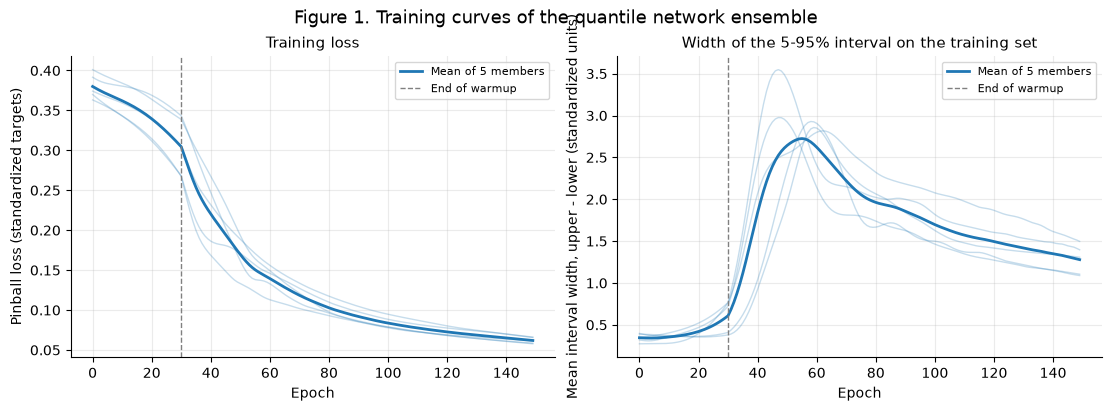

In [127]:
# Figure 1: training curves. One faint line per member, the bold line is the mean over the five members.
mean_curves = {"loss": np.mean(epoch_losses, axis=0), "width": np.mean(epoch_widths, axis=0)}
panels = [
    (epoch_losses, "loss", "Pinball loss (standardized targets)", "Training loss"),
    (epoch_widths, "width", "Mean interval width, upper - lower (standardized units)", "Width of the 5-95% interval on the training set"),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, (per_member, key, ylabel, title) in zip(axes, panels):
    for curve in per_member:
        ax.plot(curve, color="tab:blue", alpha=0.25, linewidth=1)
    ax.plot(mean_curves[key], color="tab:blue", linewidth=2, label="Mean of 5 members")
    ax.axvline(WARMUP_EPOCHS, color="gray", linestyle="--", linewidth=1, label="End of warmup")
    ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
    ax.legend()
fig.suptitle(fig_title(1, "Training curves of the quantile network ensemble"))
plt.show()

## 5. Predictions and calibration

The ensemble predicts the validation and test sets. Everything later reads from the dictionary `SPLITS`.

**Table 1** reports, per target and split:

- **R² and nRMSE of the median** in flux units (nRMSE = RMSE divided by the training-set standard deviation of that flux): how accurate the prediction is.
- **Coverage**: the fraction of true values that fall inside the interval. A calibrated 5-95% interval should cover about 0.90. A value above 0.90 means the intervals are wider than necessary, a value below means they are overconfident.

**Figure 2** (parity plot) and **Figure 3** (cases sorted by true flux) show the prediction and its interval against the true value; red marks the cases where the true value falls outside the interval.

In [128]:
SPLITS = {}
for name, X_scaled, X_raw, y_raw in [("validation", val_X_scaled, val_X_df, val_y_df), ("test", test_X_scaled, test_X_df, test_y_df)]:
    bands, spread, width = predict_ensemble(ensemble, X_scaled)
    SPLITS[name] = {"bands": bands, "y_true": y_raw.values, "X": X_raw}     # y_true in flux units, same column order as the bands

train_std = train_y_df.std().to_numpy()      # for the normalized RMSE

def evaluate(split):
    bands, y = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    rows = []
    for t, key in enumerate(TARGET_KEYS):
        median, true = bands[:, t, 1], y[:, t]
        sse = np.sum((median - true) ** 2)
        rows.append({
            "split": split, "target": key,
            "R2 (median)": 1 - sse / np.sum((true - true.mean()) ** 2),
            "nRMSE (median)": np.sqrt(sse / len(true)) / train_std[t],
            "coverage (5-95%)": np.mean((true >= bands[:, t, 0]) & (true <= bands[:, t, 2])),
        })
    return pd.DataFrame(rows)

print("Table 1. Accuracy of the median prediction and coverage of the 5-95% interval (nominal coverage 0.90)")
table_1 = pd.concat([evaluate(split) for split in SPLITS], ignore_index=True).round(3)
table_1

Table 1. Accuracy of the median prediction and coverage of the 5-95% interval (nominal coverage 0.90)


,split,target,R2 (median),nRMSE (median),coverage (5-95%)
0,validation,Q_i,0.899,0.356,0.931
1,validation,Q_e,0.902,0.325,0.943
2,validation,Gamma_e,0.721,0.566,0.973
3,test,Q_i,0.860,0.379,0.927
4,test,Q_e,0.831,0.378,0.935
5,test,Gamma_e,0.761,0.461,0.981


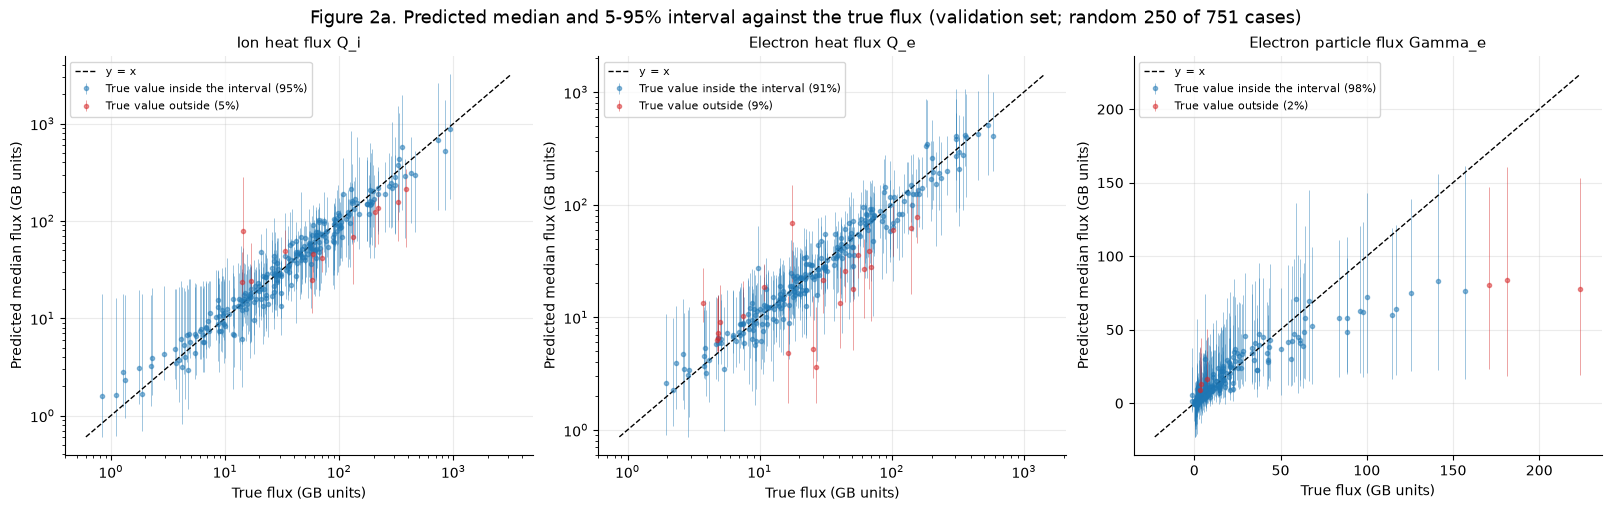

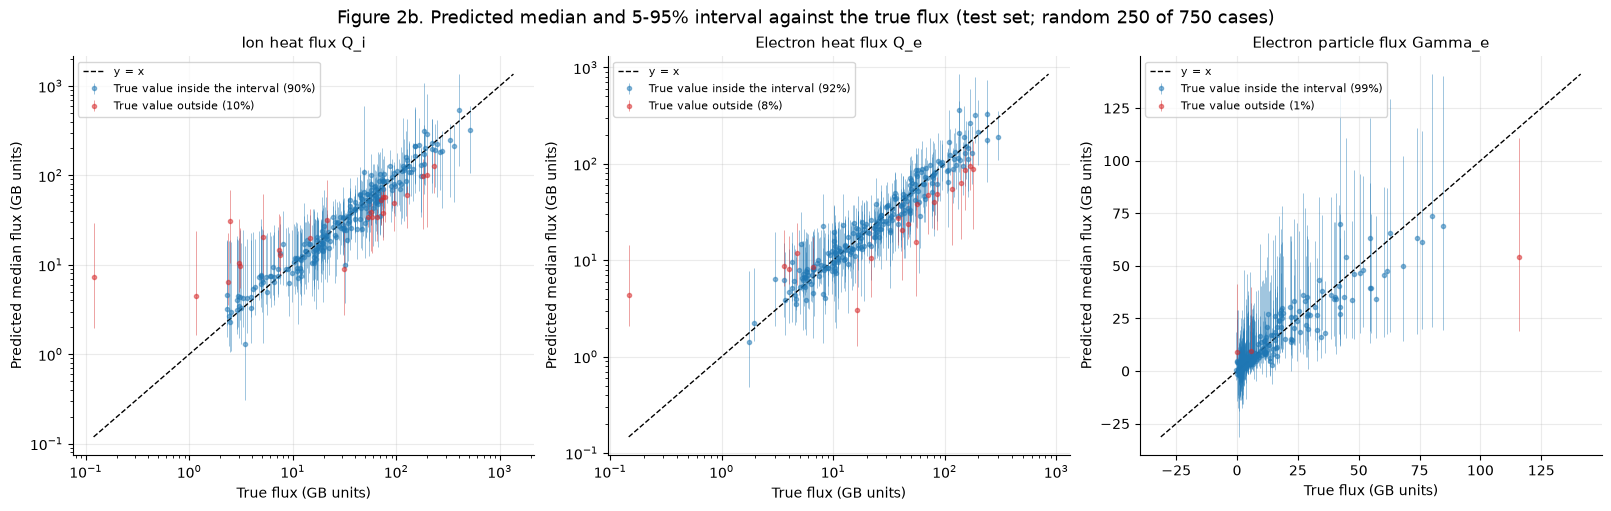

In [129]:
# Figure 2: parity plot. The true value against the predicted median, with the 5-95% interval as a vertical bar on each point.

def parity_plot(split, max_points=250, seed=0):
    bands, y_true = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    idx = np.arange(len(y_true))
    if max_points and len(idx) > max_points:
        idx = np.random.default_rng(seed).choice(idx, size=max_points, replace=False)     # a random subset keeps the bars readable
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for t, ax in enumerate(axes):
        lower, median, upper = bands[idx, t, 0], bands[idx, t, 1], bands[idx, t, 2]
        true = y_true[idx, t]
        inside = (true >= lower) & (true <= upper)
        for mask, color, label in [(inside, "tab:blue", f"True value inside the interval ({inside.mean():.0%})"),
                                   (~inside, "tab:red", f"True value outside ({1 - inside.mean():.0%})")]:
            ax.errorbar(true[mask], median[mask], yerr=[(median - lower)[mask], (upper - median)[mask]], fmt="o", ms=3, color=color,
                        ecolor=color, elinewidth=0.6, alpha=0.5, label=label)
        lims = [min(true.min(), lower.min()), max(true.max(), upper.max())]
        ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="y = x")
        if LOG_FLUX_AXIS[t]:
            ax.set(xscale="log", yscale="log")
        ax.set(xlabel="True flux (GB units)", ylabel="Predicted median flux (GB units)", title=TARGET_NAMES[t])
        ax.legend(loc="upper left")
    fig.suptitle(fig_title(2, "Predicted median and 5-95% interval against the true flux", split, note=f"random {len(idx)} of {len(y_true)} cases"))
    plt.show()

for split in SPLITS:
    parity_plot(split)

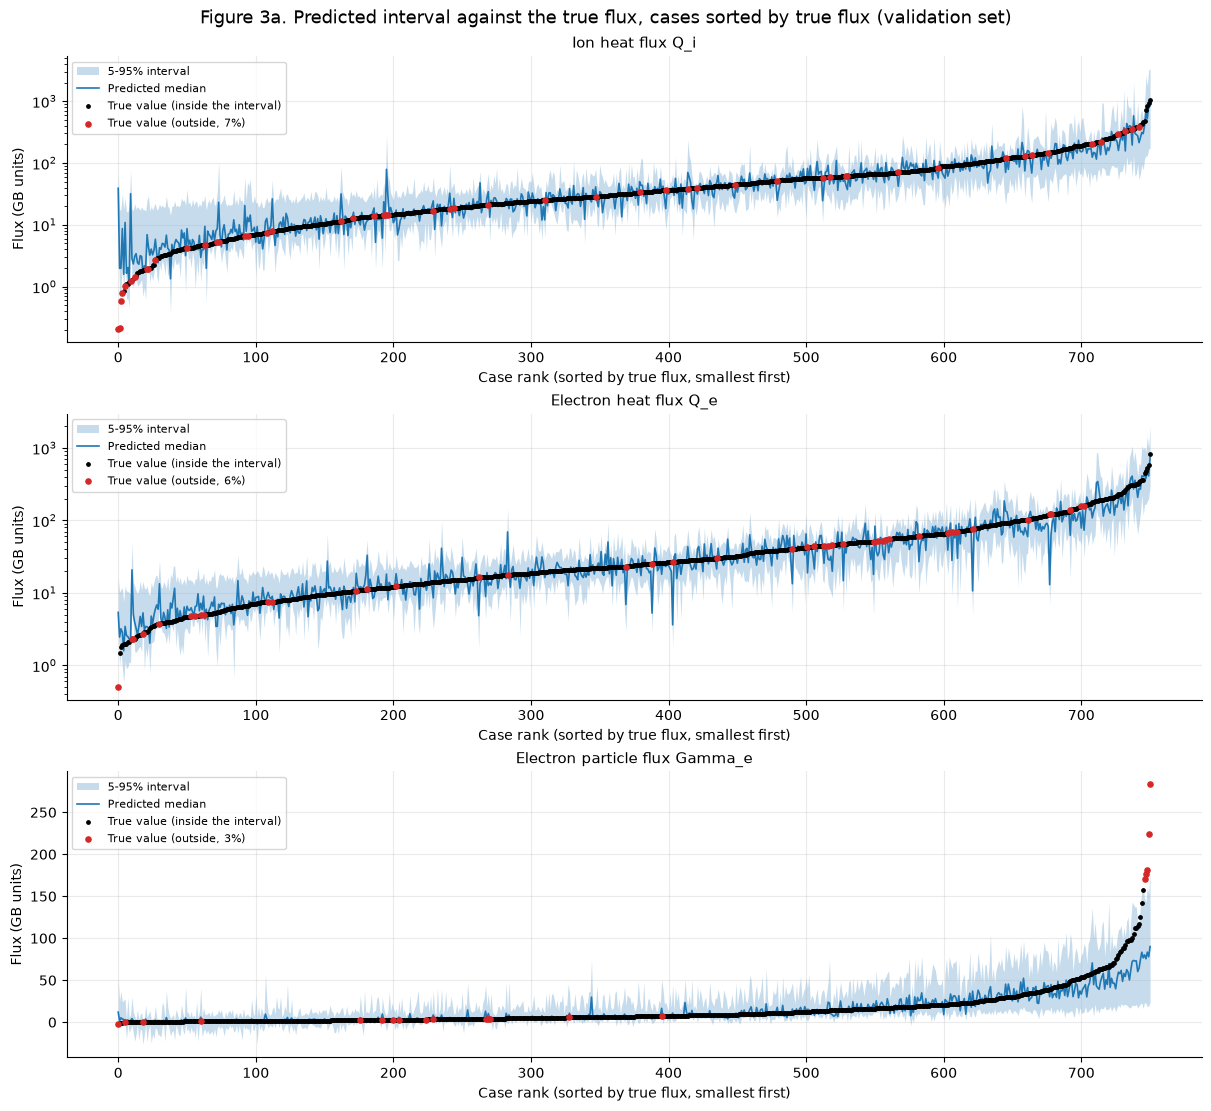

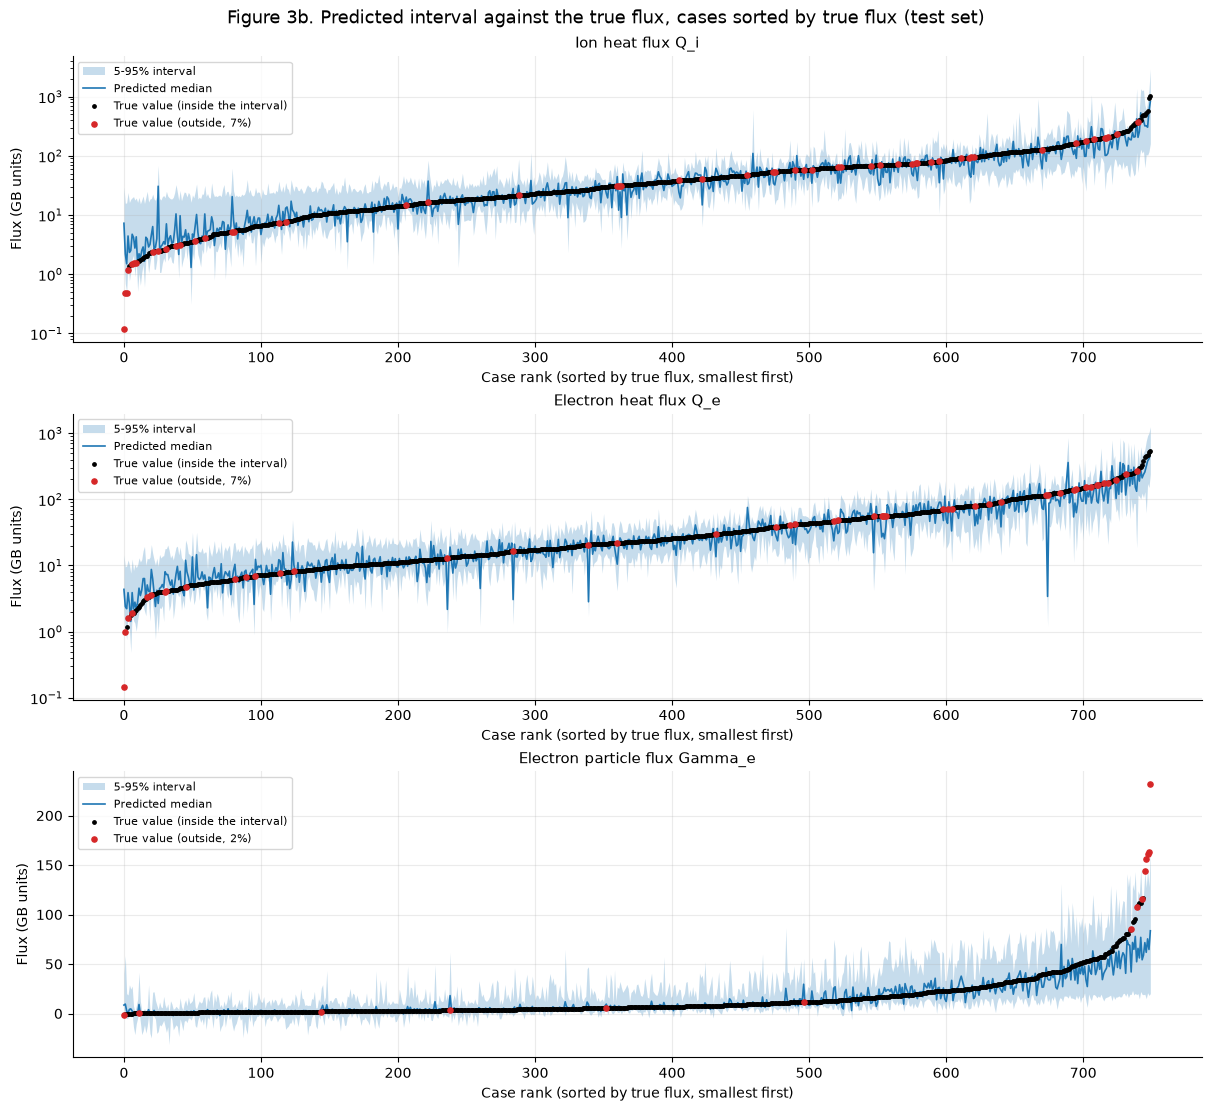

In [130]:
# Figure 3: all cases sorted by true flux (x = rank). True values as dots, the predicted median as a line, the 5-95% interval as a ribbon.

def ribbon_plot(split):
    bands, y_true = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    fig, axes = plt.subplots(3, 1, figsize=(12, 11), constrained_layout=True)
    for t, ax in enumerate(axes):
        order = np.argsort(y_true[:, t])
        x = np.arange(len(order))
        lower, median, upper = bands[order, t, 0], bands[order, t, 1], bands[order, t, 2]
        true = y_true[order, t]
        outside = (true < lower) | (true > upper)
        ax.fill_between(x, lower, upper, color="tab:blue", alpha=0.25, linewidth=0, label="5-95% interval")
        ax.plot(x, median, color="tab:blue", linewidth=1.2, label="Predicted median")
        ax.scatter(x[~outside], true[~outside], s=6, color="black", label="True value (inside the interval)", zorder=3)
        ax.scatter(x[outside], true[outside], s=14, color="tab:red", label=f"True value (outside, {outside.mean():.0%})", zorder=4)
        if LOG_FLUX_AXIS[t]:
            ax.set_yscale("log")
        ax.set(xlabel="Case rank (sorted by true flux, smallest first)", ylabel="Flux (GB units)", title=TARGET_NAMES[t])
        ax.legend(loc="upper left")
    fig.suptitle(fig_title(3, "Predicted interval against the true flux, cases sorted by true flux", split))
    plt.show()

for split in SPLITS:
    ribbon_plot(split)

## 6. What drives the width of the interval?

The width of the interval is the model's own statement of how uncertain a prediction is. This section checks whether that statement is informative: does a wider interval go with a larger error, and what makes it wide?

**Band width.** Two widths are used, because $\Gamma_e$ can be zero or negative and its lower bound can be negative:

| Target | Absolute width | Relative width |
|---|---|---|
| $Q_i$, $Q_e$ | $\ln(\text{upper} / \text{lower})$ | the same (always relative) |
| $\Gamma_e$ | upper − lower, in GB units | (upper − lower) / median, only where the median is positive |

An absolute width grows with the flux itself, so the relative width is used whenever the flux level would otherwise confound the comparison (Figures 6 to 8). Figures 4 and 5 use the absolute width for $\Gamma_e$.

**Rank correlation.** Spearman's ρ is used throughout. It measures whether two quantities rise and fall together (+1 always, −1 never) and does not assume a straight line.

In [131]:
def band_width(bands, t, relative=True):
    """Width of the interval of target t, and a mask of the cases where it is defined (see the table above)."""
    lower, median, upper = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
    everywhere = np.ones(len(lower), dtype=bool)
    if t < 2:
        return np.log(upper / lower), everywhere
    if not relative:
        return upper - lower, everywhere
    ok = median > 0
    return np.where(ok, (upper - lower) / np.where(ok, median, 1.0), np.nan), ok

def width_label(t, relative=True):
    if t < 2:
        return "Band width, ln(upper / lower)"
    return "Band width, (upper - lower) / median" if relative else "Band width, upper - lower (GB units)"

### 6.1 Error against band width (Figure 4)

Each point is one case. If the intervals carry information, the absolute error of the median should rise with the width. The red line is a least-squares fit of $\log_{10}$(error) on the width, so it shows the typical (geometric-mean) error; its slope and the Spearman correlation are in the legend and the title.
The heat-flux error is $|\ln(\text{median} / \text{true})|$, a relative error that matches the relative width; the $\Gamma_e$ error is $|\text{median} - \text{true}|$ in GB units.

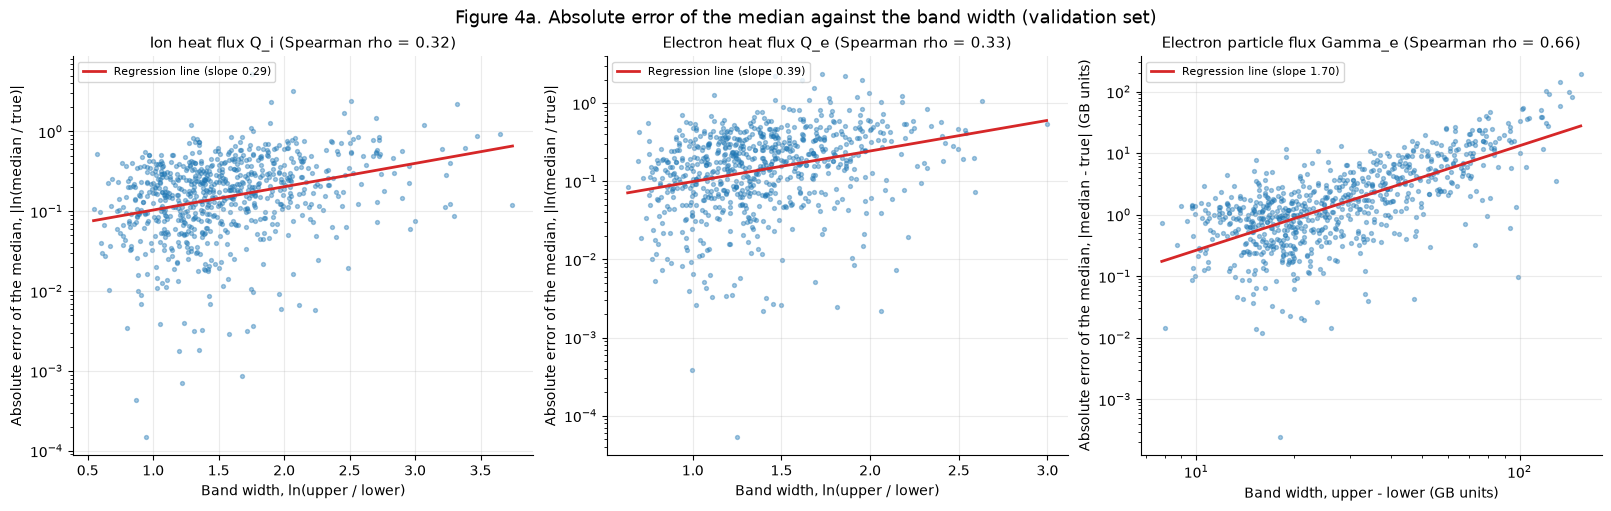

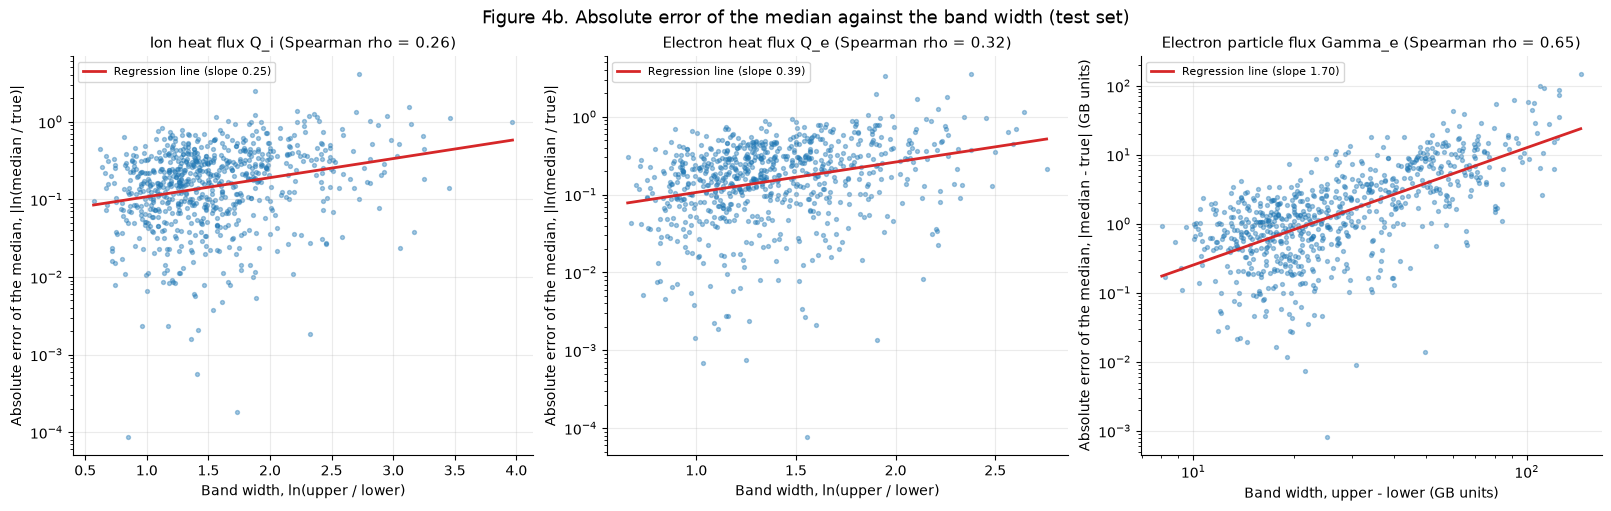

In [132]:
# Figure 4: absolute error of the median against the band width

def error_vs_width(split):
    bands, y_true = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for t, ax in enumerate(axes):
        width, _ = band_width(bands, t, relative=False)
        if t < 2:
            error = np.abs(np.log(bands[:, t, 1] / y_true[:, t]))
            error_label = "Absolute error of the median, |ln(median / true)|"
        else:
            error = np.abs(bands[:, t, 1] - y_true[:, t])
            error_label = "Absolute error of the median, |median - true| (GB units)"
        keep = (error > 0) & (width > 0)                                  # log axes cannot show zeros
        rho = pd.Series(width).corr(pd.Series(error), method="spearman")
        ax.scatter(width[keep], error[keep], s=8, alpha=0.4, color="tab:blue")
        ax.set(xscale="log" if t == 2 else "linear", yscale="log")      # the ln widths of the heat fluxes only span about 1 to 3
        # regression line, fitted in the space of the axes so that it plots as a straight line
        fx = np.log10(width[keep]) if t == 2 else width[keep]
        slope, intercept = np.polyfit(fx, np.log10(error[keep]), 1)
        xs = np.linspace(fx.min(), fx.max(), 100)
        ax.plot(10 ** xs if t == 2 else xs, 10 ** (intercept + slope * xs), color="tab:red", linewidth=2, label=f"Regression line (slope {slope:.2f})")
        ax.set(xlabel=width_label(t, relative=False), ylabel=error_label, title=f"{TARGET_NAMES[t]} (Spearman rho = {rho:.2f})")
        ax.legend(loc="upper left")
    fig.suptitle(fig_title(4, "Absolute error of the median against the band width", split))
    plt.show()

for split in SPLITS:
    error_vs_width(split)

### 6.2 Band width against the true flux (Figure 5)

Does the interval get wider or narrower across the flux range? The x-axis is the true flux on a log scale, so the few cases with a non-positive $\Gamma_e$ are left out of that panel.

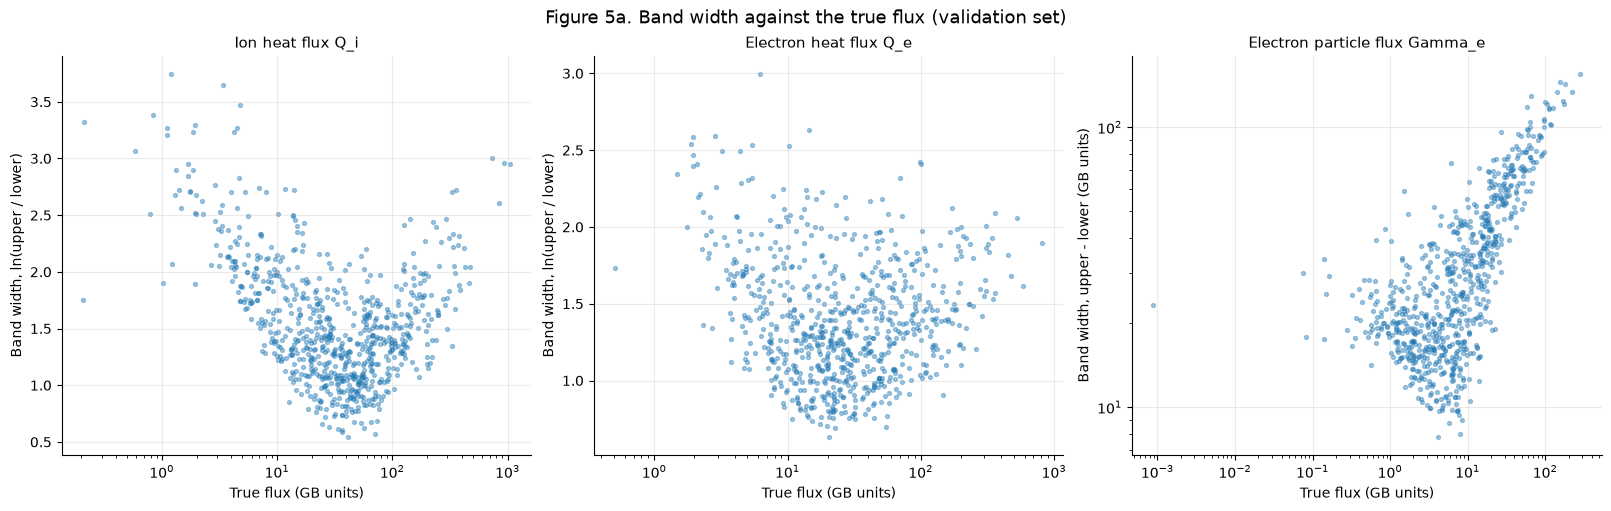

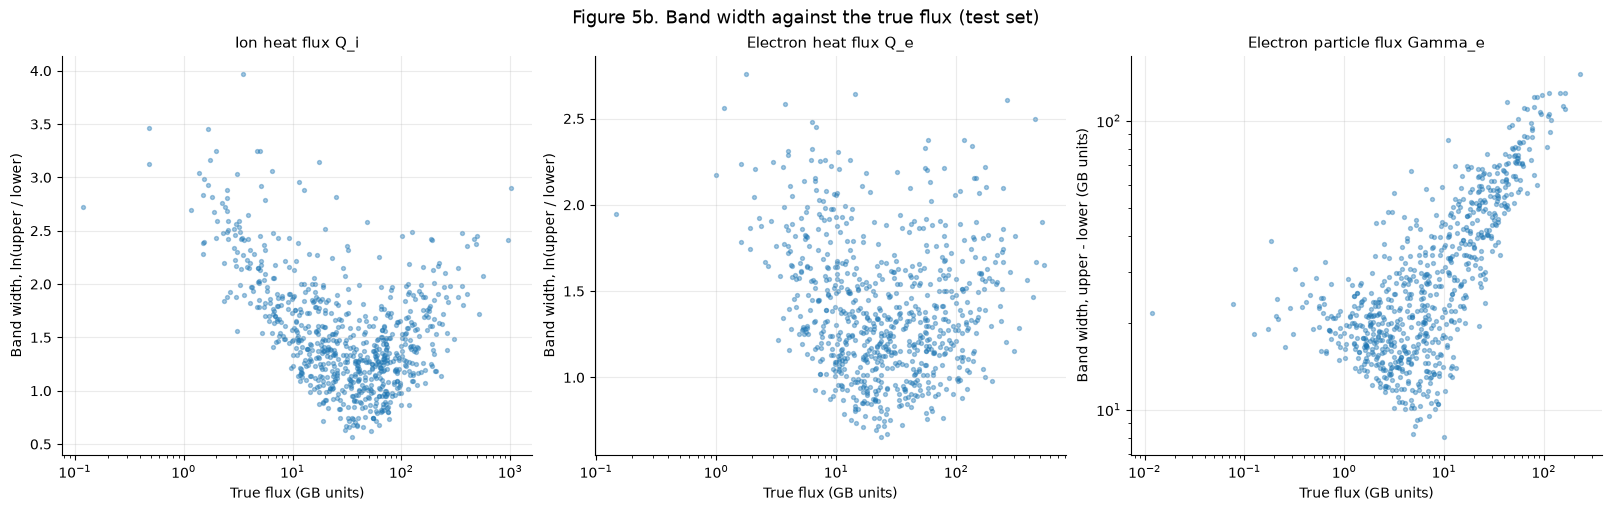

In [133]:
# Figure 5: band width against the true flux

def width_vs_flux(split):
    bands, y_true = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for t, ax in enumerate(axes):
        width, _ = band_width(bands, t, relative=False)
        keep = y_true[:, t] > 0
        ax.scatter(y_true[keep, t], width[keep], s=8, alpha=0.4, color="tab:blue")
        ax.set(xscale="log", yscale="log" if t == 2 else "linear", xlabel="True flux (GB units)", ylabel=width_label(t, relative=False), title=TARGET_NAMES[t])
    fig.suptitle(fig_title(5, "Band width against the true flux", split))
    plt.show()

for split in SPLITS:
    width_vs_flux(split)

### 6.3 Band width and the amount of training data (Figure 6)

Is the interval wider where the model has seen less data? The training flux range of each target is cut into `N_FLUX_BINS` equal-width bins on a log scale. For every bin, the x-value is the **number of training cases** in the bin and the y-value is the **average relative band width** of the evaluation cases whose true flux lies in it (bins with fewer than `MIN_CASES_PER_BIN` such cases are not shown).

- **Left panels:** one point per bin, with a trend line against $\log_{10}$(count) and the Spearman correlation across bins.
- **Right panels:** the same bins sorted by training count and split into three equal groups (fewest, middle, most data), with the average width of each group.

The top row shows the heat fluxes (same unit, shared axis); $\Gamma_e$ has a different width unit and is in the bottom row.

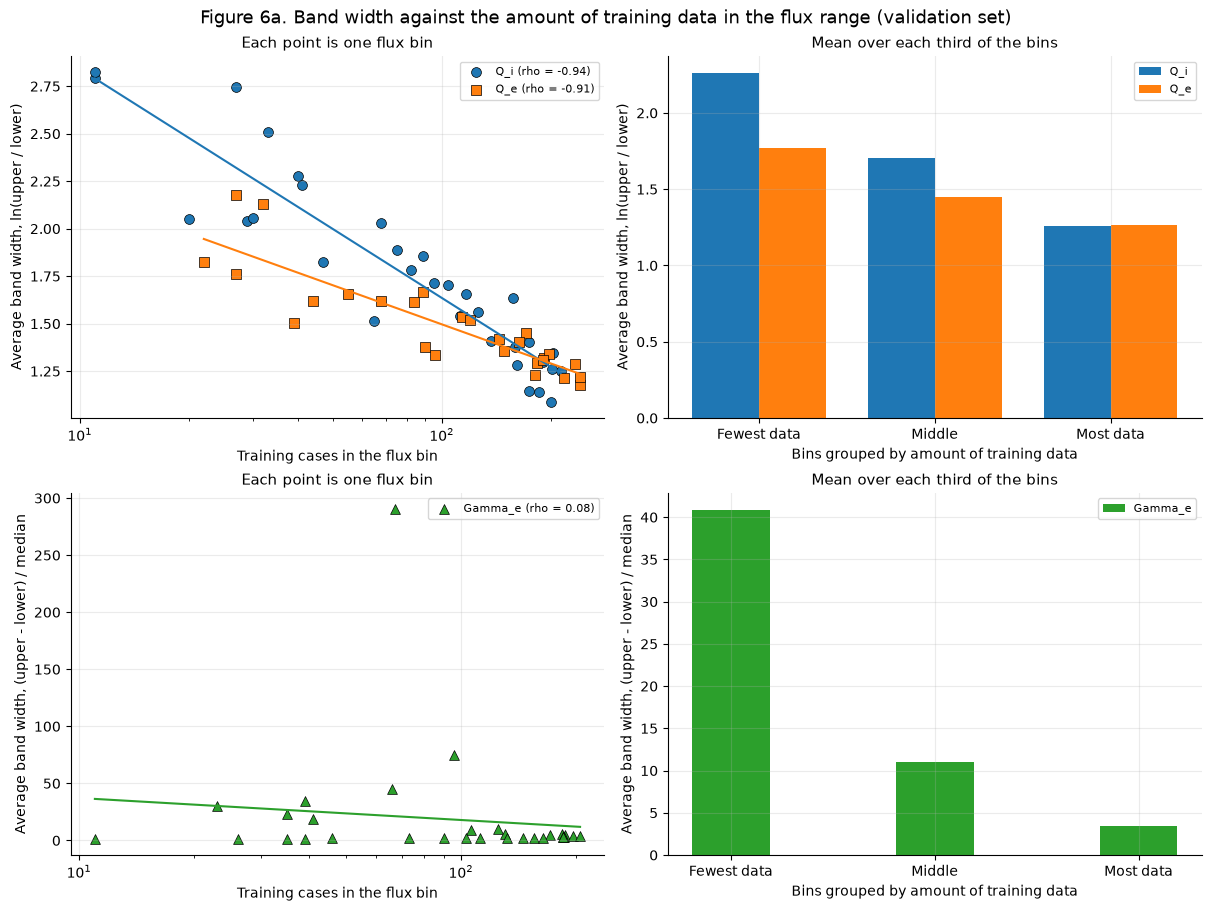

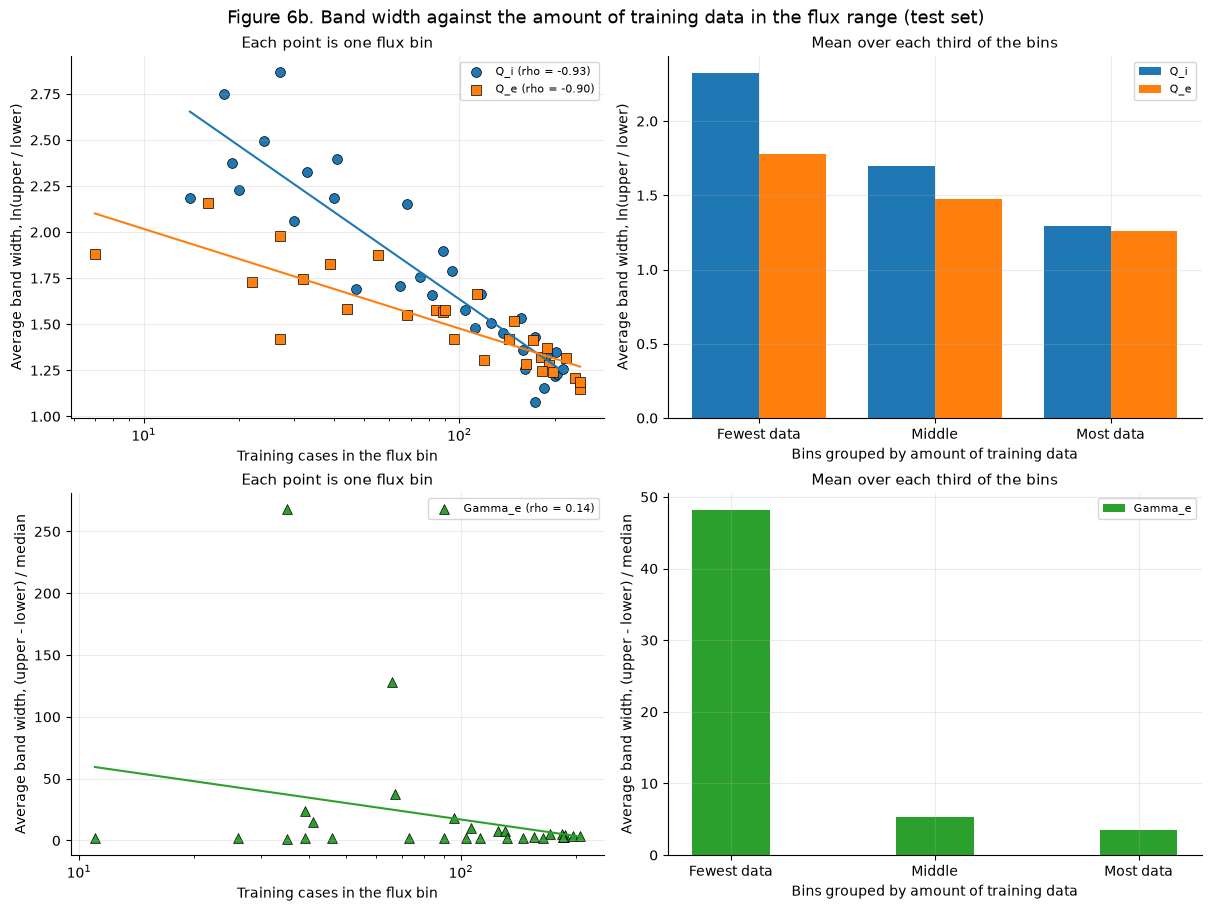

In [134]:
# Figure 6: average band width against the number of training cases in the flux bin

def bin_counts_and_widths(bands, y_true, t):
    """For each log10 flux bin: the number of training cases in it, and the mean relative band width of the evaluation cases in it."""
    width, ok = band_width(bands, t, relative=True)
    train_true = train_y_df.values
    train = np.log10(train_true[train_true[:, t] > 0, t])
    edges = np.linspace(train.min(), train.max(), N_FLUX_BINS + 1)
    train_counts = np.histogram(train, bins=edges)[0]
    keep = (y_true[:, t] > 0) & ok
    flux = np.log10(y_true[keep, t])
    inside = (flux >= edges[0]) & (flux <= edges[-1])
    which = np.clip(np.digitize(flux, edges) - 1, 0, N_FLUX_BINS - 1)
    counts, widths = [], []
    for b in range(N_FLUX_BINS):
        selected = inside & (which == b)
        if selected.sum() >= MIN_CASES_PER_BIN:
            counts.append(train_counts[b])
            widths.append(width[keep][selected].mean())
    return np.array(counts), np.array(widths)

def training_data_figure(split):
    bands, y_true = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    group_names = ["Fewest data", "Middle", "Most data"]
    for (targets, ylabel), (ax_points, ax_bars) in zip([([0, 1], width_label(0)), ([2], width_label(2))], axes):
        for position, t in enumerate(targets):
            counts, widths = bin_counts_and_widths(bands, y_true, t)
            rho = pd.Series(counts).corr(pd.Series(widths), method="spearman")
            ax_points.scatter(counts, widths, s=50, color=TARGET_COLORS[t], marker=TARGET_MARKERS[t], edgecolor="black", linewidth=0.5,
                              label=f"{TARGET_KEYS[t]} (rho = {rho:.2f})")
            slope, intercept = np.polyfit(np.log10(counts), widths, 1)
            grid = np.linspace(counts.min(), counts.max(), 100)
            ax_points.plot(grid, intercept + slope * np.log10(grid), color=TARGET_COLORS[t], linewidth=1.5)
            thirds = np.array_split(np.argsort(counts), 3)                  # bins sorted by training count, split into three equal groups
            offset = (position - (len(targets) - 1) / 2) * 0.38
            ax_bars.bar(np.arange(3) + offset, [widths[g].mean() for g in thirds], width=0.38, color=TARGET_COLORS[t], label=TARGET_KEYS[t])
        ax_points.set(xscale="log", xlabel="Training cases in the flux bin", ylabel="Average " + ylabel[0].lower() + ylabel[1:], title="Each point is one flux bin")
        ax_bars.set(xticks=range(3), xticklabels=group_names, xlabel="Bins grouped by amount of training data", ylabel="Average " + ylabel[0].lower() + ylabel[1:],
                    title="Mean over each third of the bins")
        ax_points.legend()
        ax_bars.legend()
    fig.suptitle(fig_title(6, "Band width against the amount of training data in the flux range", split))
    plt.show()

for split in SPLITS:
    training_data_figure(split)

### 6.4 Band width against the input parameters (Figures 7 and 8)

Which inputs make the interval wide? Inputs are shown in their original (unscaled) units.

- **Figure 7:** for each input, the cases are grouped into `N_INPUT_BINS` bins with equal numbers of cases (one group per value for an input with five or fewer values, such as `MASS_2`). The line is the median relative band width in each bin, divided by that target's overall median, so all three targets share one axis: 1 means the usual width.
- **Figure 8:** the Spearman correlation between each input and the relative band width (negative: a larger input goes with a narrower interval).

Inputs also move the flux itself, so a correlation here can partly reflect the flux level. This applies most to $\Gamma_e$, whose relative width is inflated where the median is close to zero.

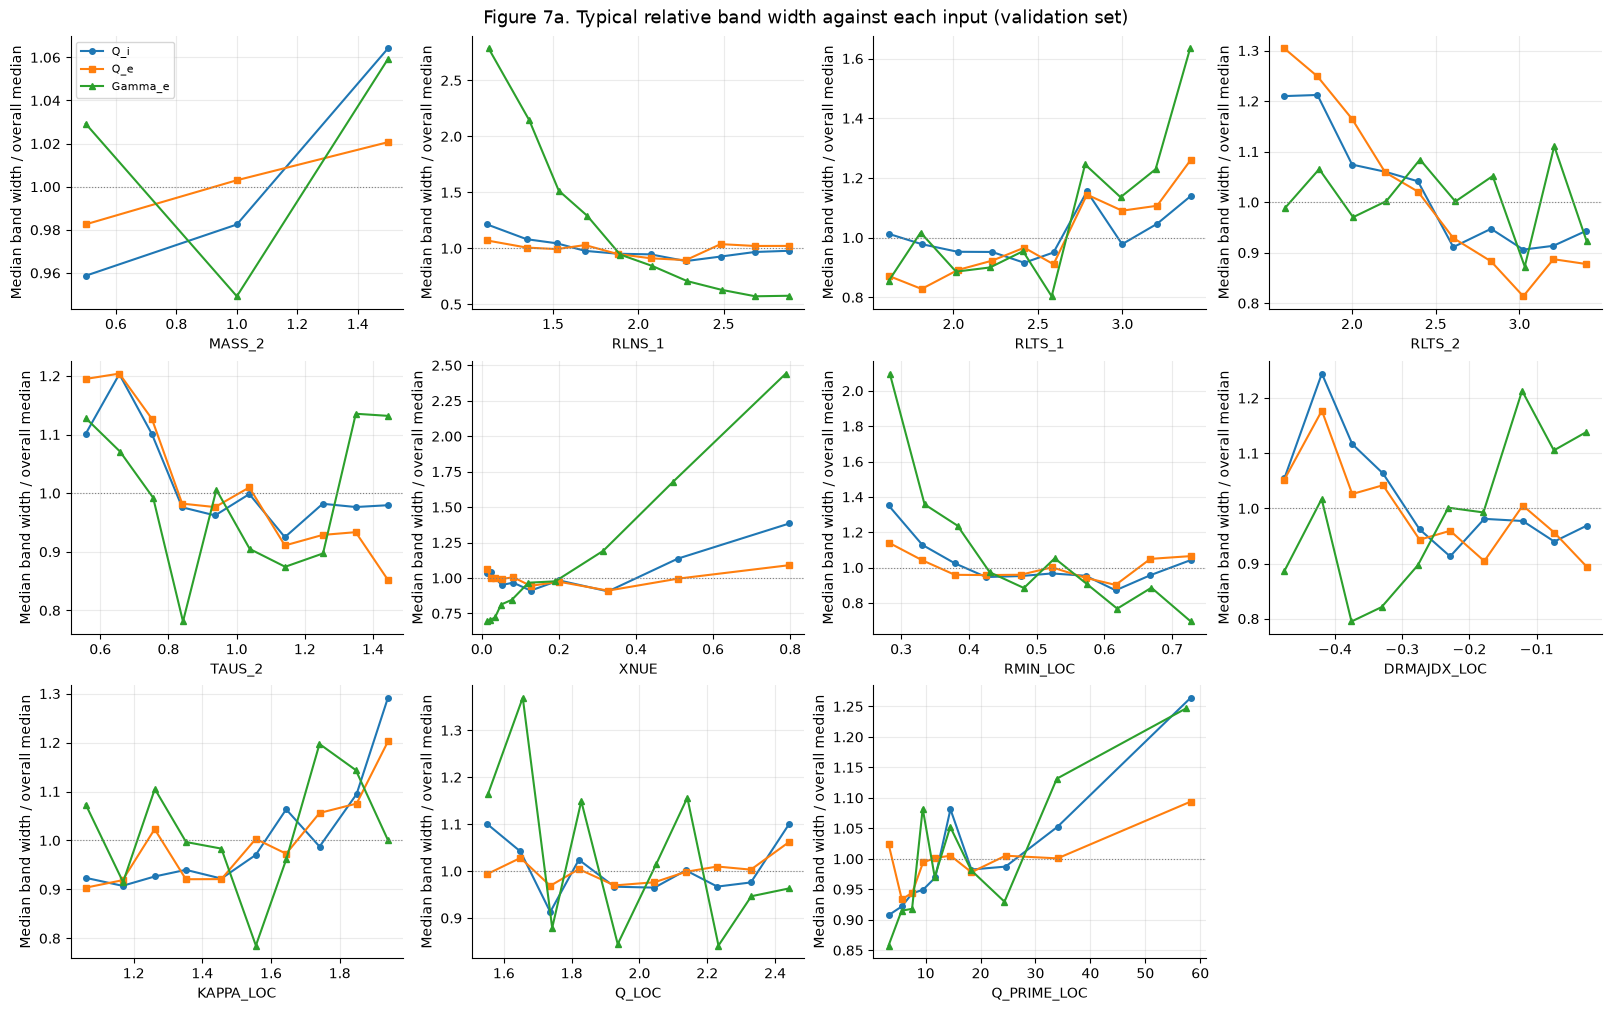

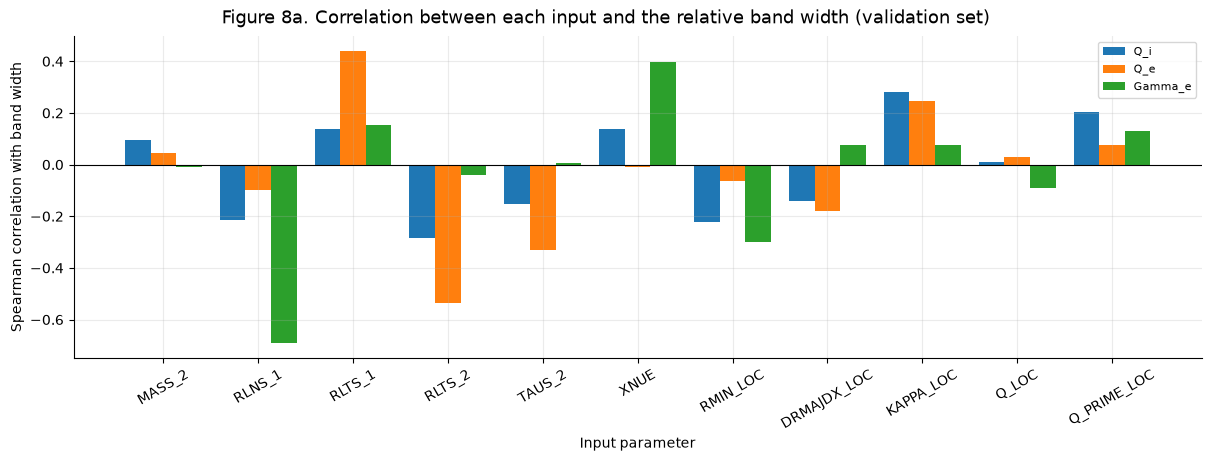

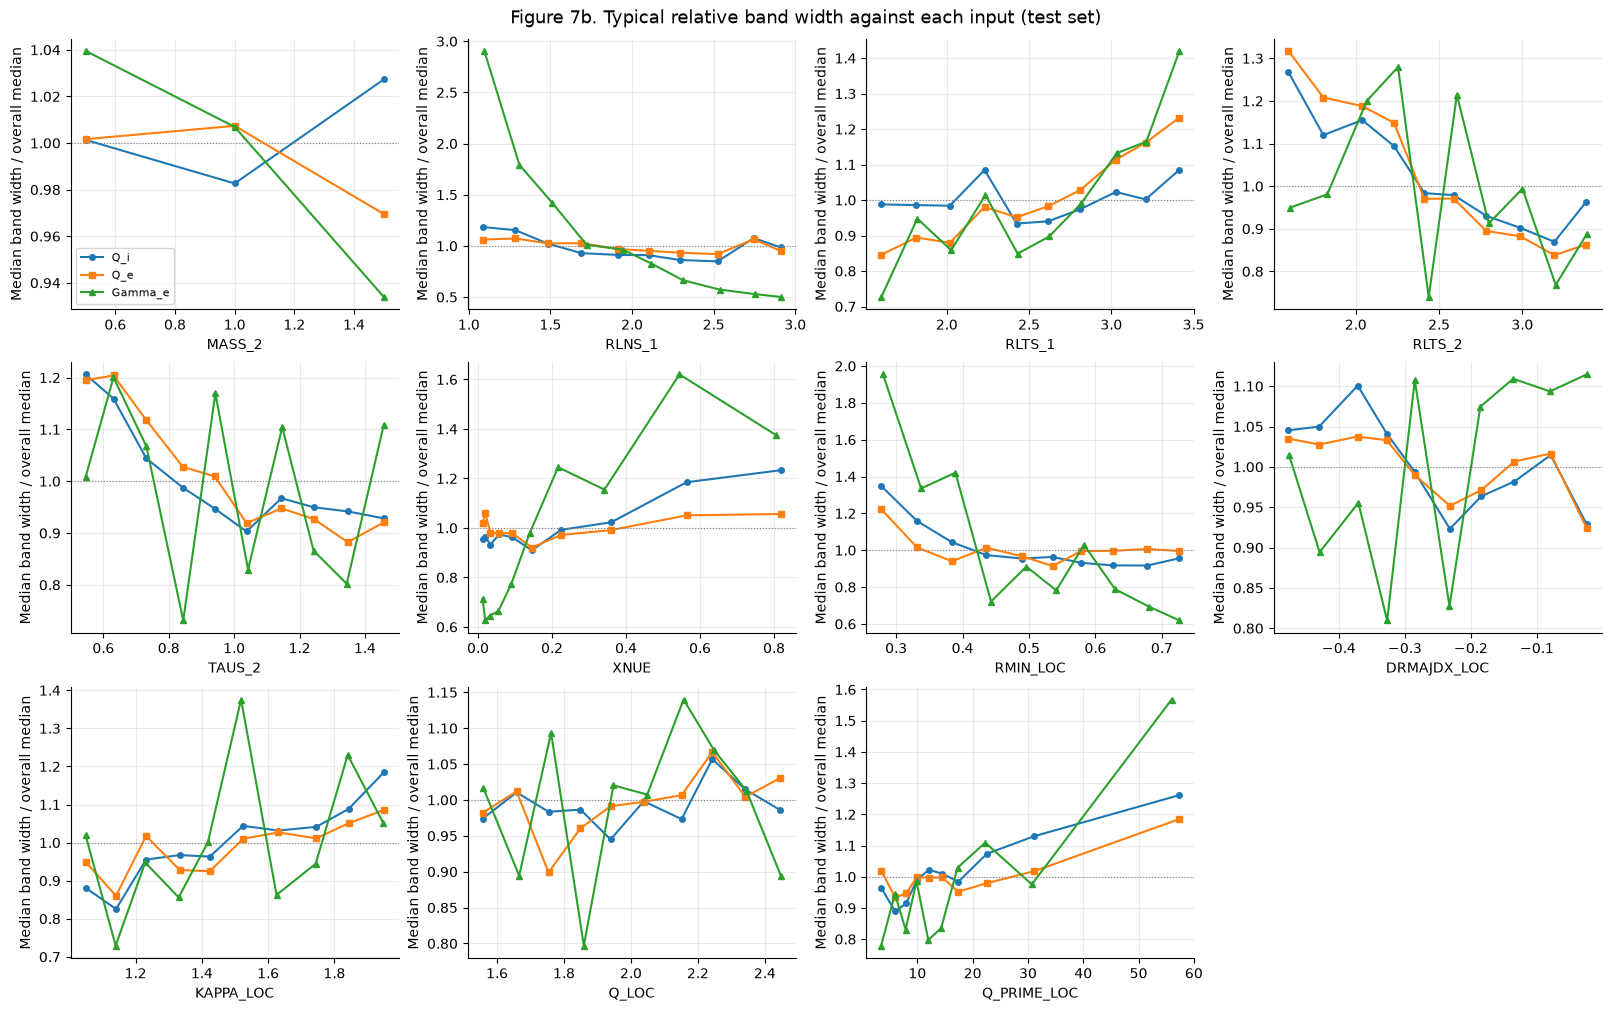

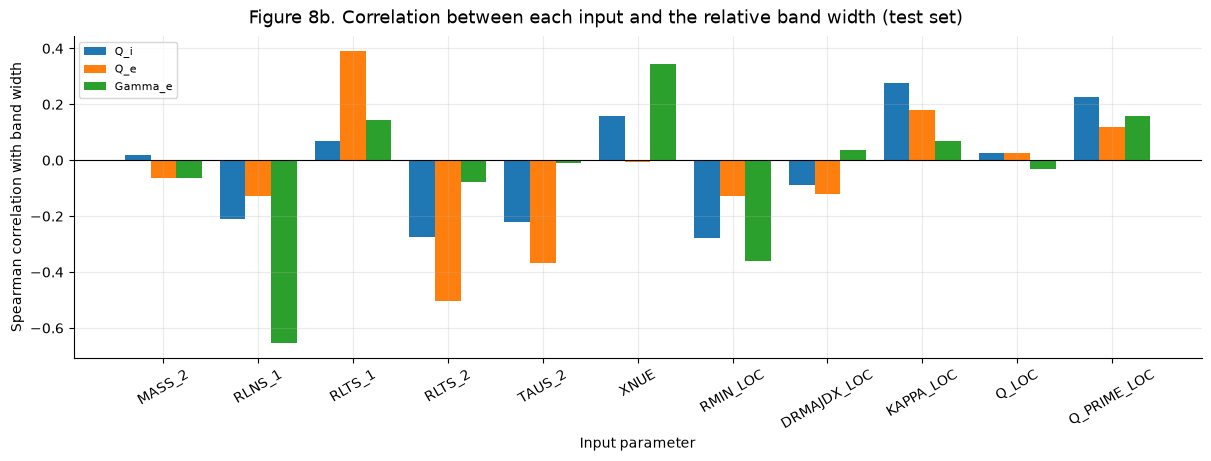

In [135]:
# Figures 7 and 8: relative band width against each input

def width_vs_inputs(split):
    bands, X = SPLITS[split]["bands"], SPLITS[split]["X"]
    features = list(X.columns)
    widths = [band_width(bands, t, relative=True) for t in range(3)]
    rho = pd.DataFrame(index=features, columns=TARGET_KEYS, dtype=float)

    fig, axes = plt.subplots(3, 4, figsize=(16, 10), constrained_layout=True)
    for ax, feature in zip(axes.flat, features):
        for t in range(3):
            width, ok = widths[t]
            frame = pd.DataFrame({"x": X[feature].to_numpy()[ok], "w": width[ok]})
            groups = frame["x"] if frame["x"].nunique() <= 5 else pd.qcut(frame["x"], N_INPUT_BINS, duplicates="drop")
            binned = frame.groupby(groups, observed=True).agg(x=("x", "mean"), w=("w", "median"))
            ax.plot(binned["x"], binned["w"] / frame["w"].median(), color=TARGET_COLORS[t], marker=TARGET_MARKERS[t], markersize=4, linewidth=1.5, label=TARGET_KEYS[t])
            rho.loc[feature, TARGET_KEYS[t]] = frame["x"].corr(frame["w"], method="spearman")
        ax.axhline(1, color="gray", linewidth=0.8, linestyle=":")
        ax.set(xlabel=feature, ylabel="Median band width / overall median")
    for ax in axes.flat[len(features):]:
        ax.axis("off")
    axes.flat[0].legend()
    fig.suptitle(fig_title(7, "Typical relative band width against each input", split))
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
    positions = np.arange(len(features))
    for t in range(3):
        ax.bar(positions + (t - 1) * 0.27, rho[TARGET_KEYS[t]], width=0.27, color=TARGET_COLORS[t], label=TARGET_KEYS[t])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xticks=positions, xticklabels=features, xlabel="Input parameter", ylabel="Spearman correlation with band width")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
    fig.suptitle(fig_title(8, "Correlation between each input and the relative band width", split))
    plt.show()
    return rho

correlations = {split: width_vs_inputs(split) for split in SPLITS}

In [136]:
# Table 2: the correlations plotted in Figure 8
print("Table 2. Spearman correlation between each input and the relative band width")
table_2 = pd.concat(correlations, axis=1).round(2)
table_2

Table 2. Spearman correlation between each input and the relative band width


validation                test              
                   Q_i   Q_e Gamma_e   Q_i   Q_e Gamma_e
MASS_2            0.10  0.05   -0.01  0.02 -0.06   -0.06
RLNS_1           -0.21 -0.10   -0.69 -0.21 -0.13   -0.66
RLTS_1            0.14  0.44    0.15  0.07  0.39    0.15
RLTS_2           -0.28 -0.53   -0.04 -0.27 -0.50   -0.08
TAUS_2           -0.15 -0.33    0.01 -0.22 -0.37   -0.01
XNUE              0.14 -0.01    0.40  0.16 -0.01    0.34
RMIN_LOC         -0.22 -0.06   -0.30 -0.28 -0.13   -0.36
DRMAJDX_LOC      -0.14 -0.18    0.07 -0.09 -0.12    0.04
KAPPA_LOC         0.28  0.25    0.07  0.28  0.18    0.07
Q_LOC             0.01  0.03   -0.09  0.02  0.03   -0.03
Q_PRIME_LOC       0.20  0.08    0.13  0.23  0.12    0.16

## 7. Out-of-range inputs

The nine tables `data/ood_*_table.csv` (built from `scan_db_outside/` with `tglf_dataset.py`) each hold 30 TGLF runs in which **one input is pushed beyond the range covered by the training scan** while every other input stays inside it:

| Table | Input pushed out of range | Scan range | Values in the table |
|---|---|---|---|
| `ood_RLTS_1` | RLTS_1 | 1.5 to 3.5 | 3.5 to 5.0 |
| `ood_RLTS_2` | RLTS_2 | 1.5 to 3.5 | 3.5 to 5.0 |
| `ood_RLN` | RLNS_1 (RLNS_2 moves with it) | 1 to 3 | 3.0 to 4.5 |
| `ood_TAUS_2` | TAUS_2 | 0.5 to 1.5 | 1.5 to 2.5 |
| `ood_XNUE` | XNUE | 0.01 to 1 | 1.05 to 4.8 |
| `ood_Q_LOC` | Q_LOC | 1.5 to 2.5 | 2.5 to 4.0 |
| `ood_KAPPA_LOC` | KAPPA_LOC | 1 to 2 | 2.0 to 2.5 |
| `ood_DRMAJDX_LOC` | DRMAJDX_LOC | -0.5 to 0 | -0.75 to -0.5 |
| `ood_RMIN_LOC` | RMIN_LOC | 0.25 to 0.75 | 0.75 to 0.9 |

The ensemble from Section 4 is applied to each table **without any retraining**. The tables go through the same preprocessing as the training data: the same dropped features and the scaler fitted on the training set, with nothing refit.

- **Table 3** scores each table like Table 1, next to the in-range test set for reference. The new column is the median relative band width (defined in Section 6).
- **Figures 9a to 9i** are parity plots, one per table.
- **Figure 10** shows the band width against the value of the out-of-range input. Each target's width is divided by its median width on the in-range test set, so 1 means "as wide as usual". Each target has a regression line (a least-squares fit of the log of the width on the input value). **Table 4** gives the Spearman correlation between the distance beyond that edge and the width.

If the intervals are informative outside the training range, the band should widen as the input moves further out, and the coverage should stay near 0.90. A coverage well below 0.90 means the model is overconfident where it has no data.

In [137]:
# apply the trained ensemble to every out-of-range table, with the same preprocessing as the training data (nothing is refit)

OOD_PARAMS = {   # table -> the input that was pushed outside the scan range
    "ood_RLTS_1": "RLTS_1", "ood_RLTS_2": "RLTS_2", "ood_RLN": "RLNS_1", "ood_TAUS_2": "TAUS_2", "ood_XNUE": "XNUE",
    "ood_Q_LOC": "Q_LOC", "ood_KAPPA_LOC": "KAPPA_LOC", "ood_DRMAJDX_LOC": "DRMAJDX_LOC", "ood_RMIN_LOC": "RMIN_LOC",
}

def prepare_ood(name):
    """Read one out-of-range table and return it with its scaled input features and its three target fluxes."""
    table = pd.read_csv(f"data/{name}_table.csv")
    X = encode_categoricals(table.drop(columns=ALL_FLUX_COLS))[0]                       # same steps as the training data (step 2)
    y = table[OUTPUT_COLS]
    ok = valid_rows(X, y)
    X = X[ok].drop(columns=high_corr_features + low_variance_features, errors="ignore")
    missing = [c for c in train_X_df.columns if c not in X.columns]
    assert not missing, f"{name} lacks the training features {missing}"
    X = X[train_X_df.columns]                                                              # the training columns, in the training order
    X_scaled = X.copy()
    continuous = list(scaler.feature_names_in_)
    X_scaled[continuous] = scaler.transform(X[continuous])                                 # the scaler fitted on the training set
    return table[ok], X_scaled, y[ok]

OOD_SETS = {}
for name, param in OOD_PARAMS.items():
    table, X_scaled, y = prepare_ood(name)
    bands, _, _ = predict_ensemble(ensemble, X_scaled)
    OOD_SETS[name] = {"param": param, "bands": bands, "y_true": y.values, "value": table[param].to_numpy(),
                      "scan_range": (df[param].min(), df[param].max())}

def score_bands(bands, y_true):
    """Accuracy of the median, coverage and typical relative band width, per target."""
    rows = []
    for t, key in enumerate(TARGET_KEYS):
        median, true = bands[:, t, 1], y_true[:, t]
        sse = np.sum((median - true) ** 2)
        rows.append({
            "target": key,
            "R2 (median)": 1 - sse / np.sum((true - true.mean()) ** 2),
            "nRMSE (median)": np.sqrt(sse / len(true)) / train_std[t],
            "coverage (5-95%)": np.mean((true >= bands[:, t, 0]) & (true <= bands[:, t, 2])),
            "median relative band width": np.nanmedian(band_width(bands, t, relative=True)[0]),
        })
    return pd.DataFrame(rows)

print("Table 3. Accuracy, coverage and band width on the out-of-range tables (30 runs each), next to the in-range test set")
reference_sets = [("test set (in range)", SPLITS["test"])] + list(OOD_SETS.items())
table_3 = pd.concat([score_bands(s["bands"], s["y_true"]).assign(dataset=name) for name, s in reference_sets], ignore_index=True)
table_3 = table_3[["dataset", "target", "R2 (median)", "nRMSE (median)", "coverage (5-95%)", "median relative band width"]].round(3)
table_3

Table 3. Accuracy, coverage and band width on the out-of-range tables (30 runs each), next to the in-range test set


,dataset,target,R2 (median),nRMSE (median),coverage (5-95%),median relative band width
0,test set (in range),Q_i,0.860,0.379,0.927,1.434
1,test set (in range),Q_e,0.831,0.378,0.935,1.325
2,test set (in range),Gamma_e,0.761,0.461,0.981,3.243
3,ood_RLTS_1,Q_i,0.825,0.381,0.933,1.776
4,ood_RLTS_1,Q_e,0.614,0.935,0.833,1.958
5,ood_RLTS_1,Gamma_e,0.750,0.456,0.967,4.783
6,ood_RLTS_2,Q_i,0.786,1.435,0.967,1.729
7,ood_RLTS_2,Q_e,0.716,0.832,0.967,1.219
8,ood_RLTS_2,Gamma_e,0.578,0.988,0.967,3.386
9,ood_RLN,Q_i,0.930,0.713,0.900,1.724


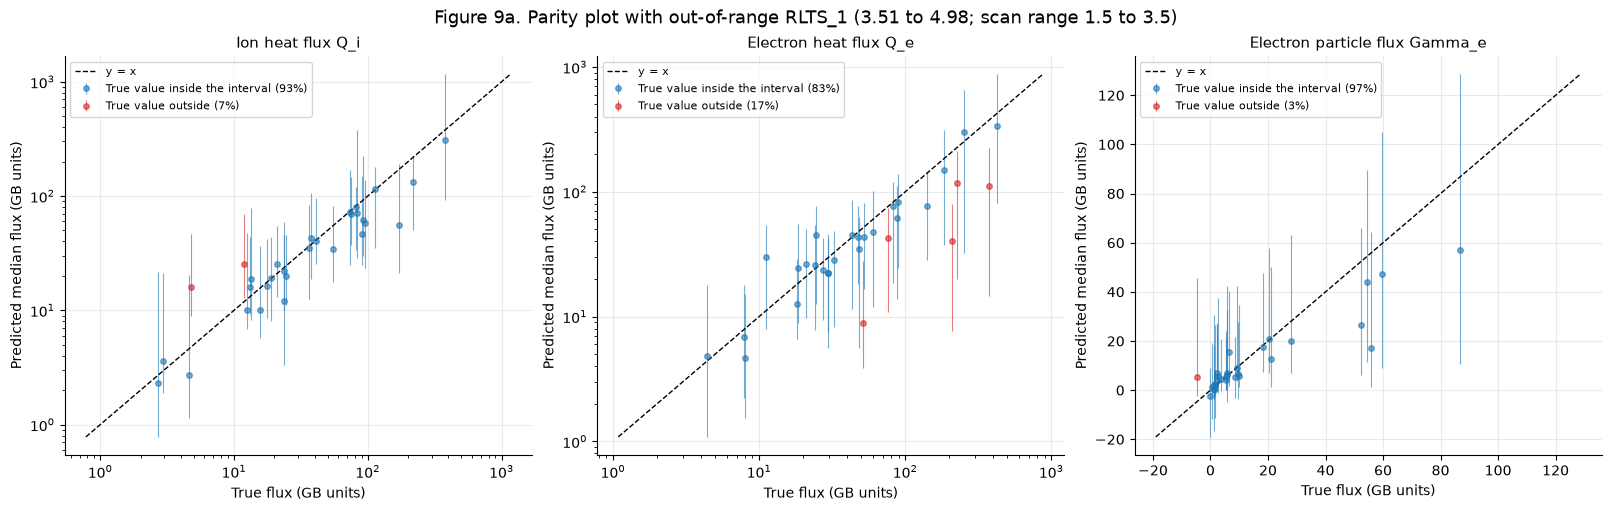

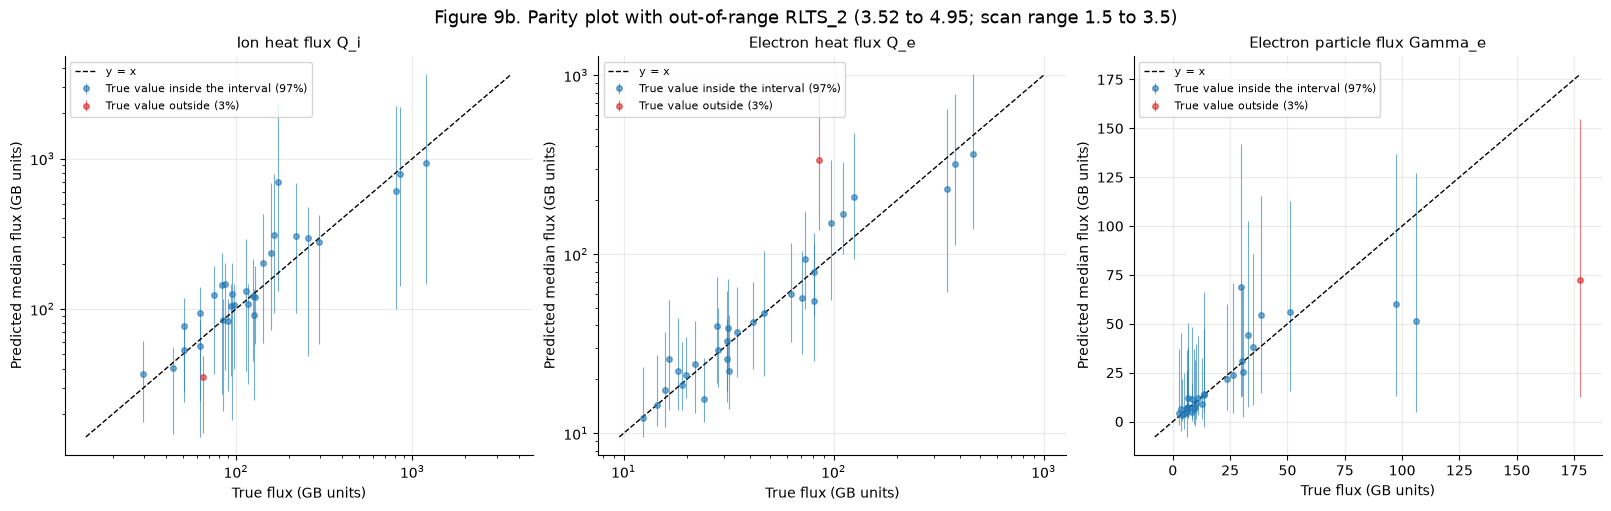

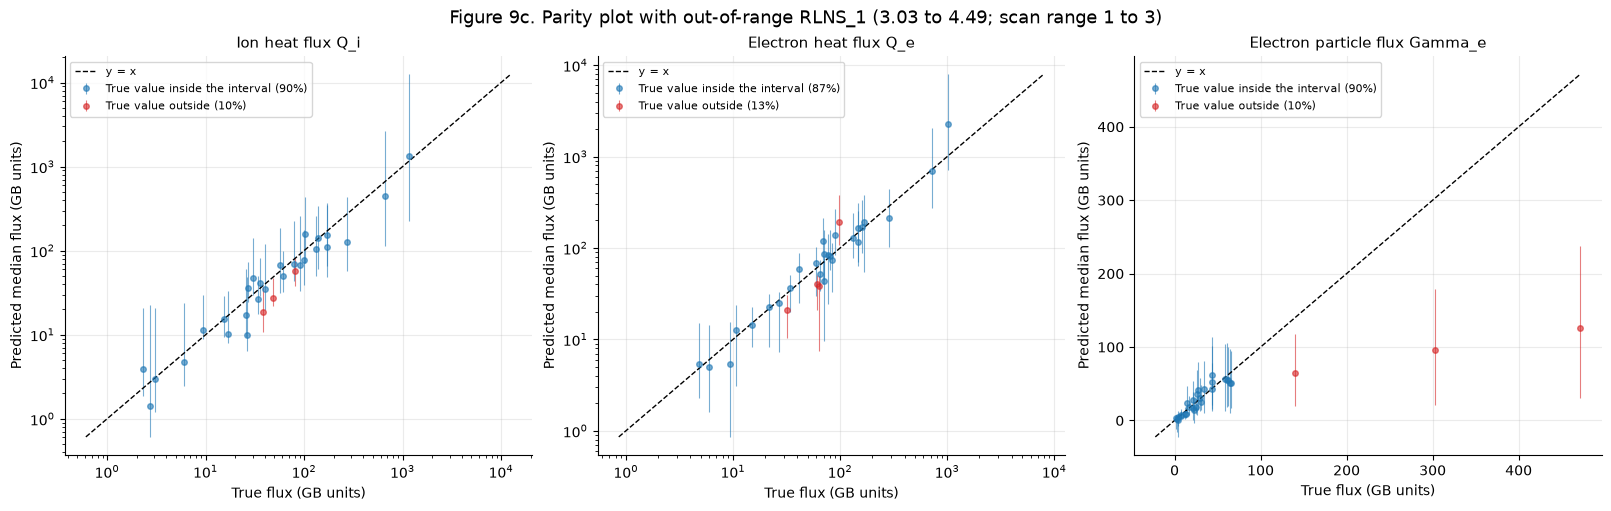

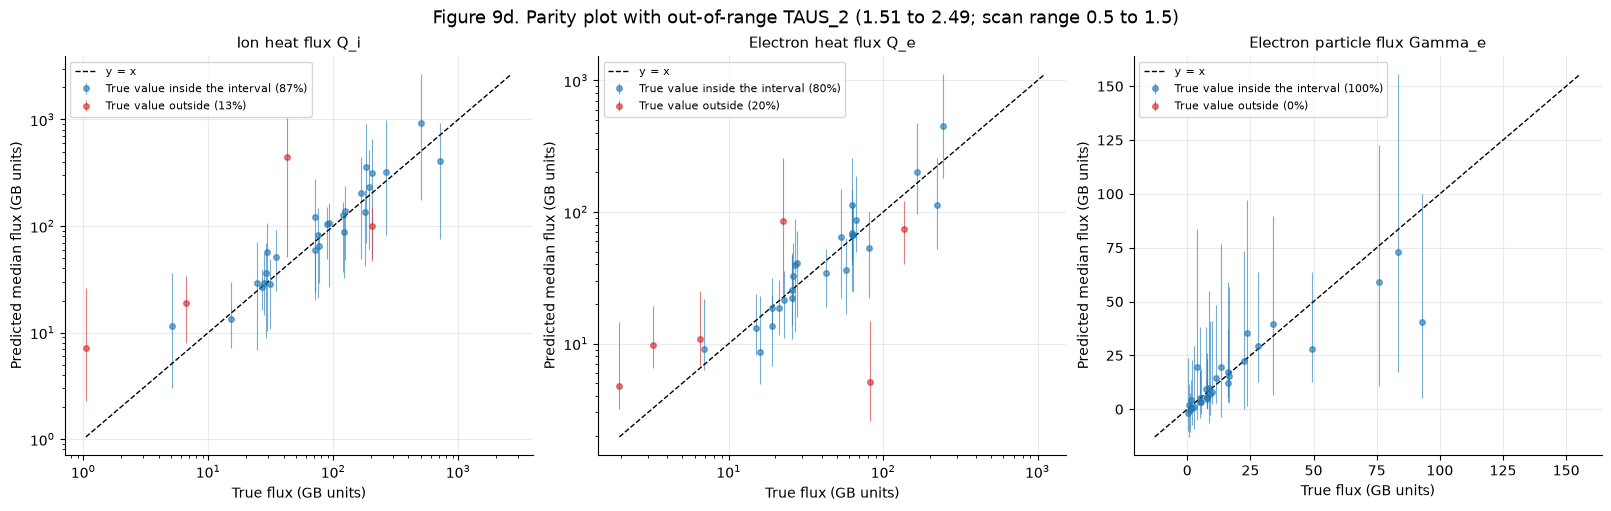

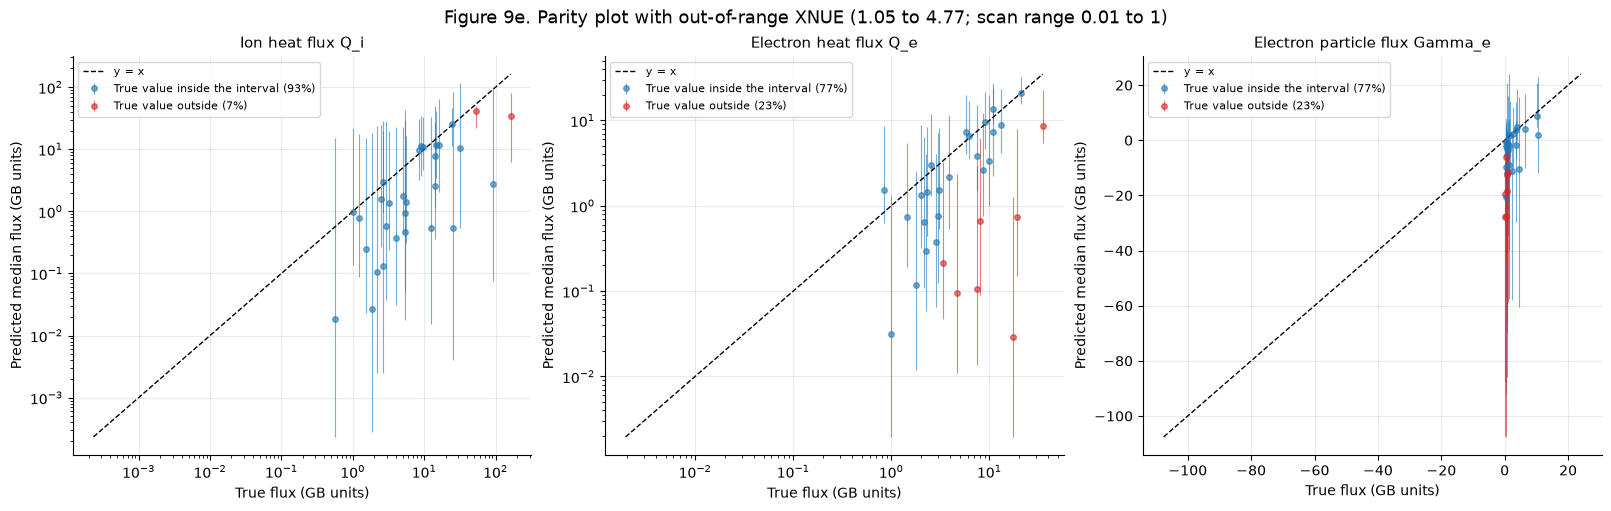

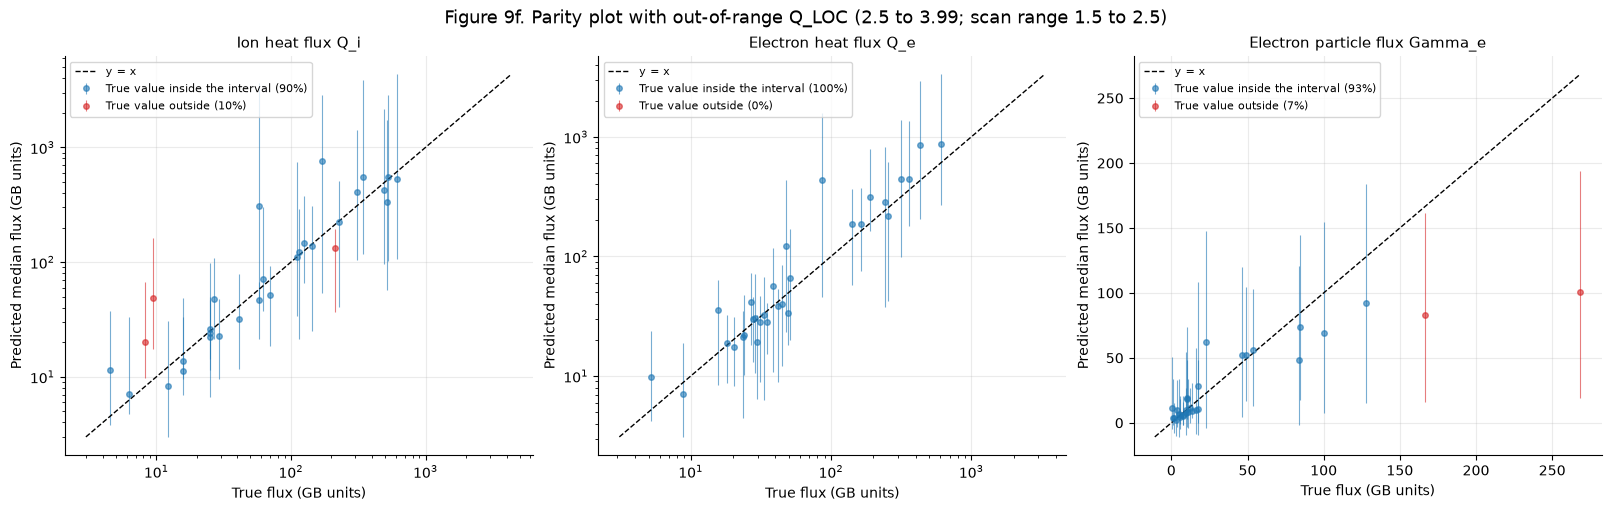

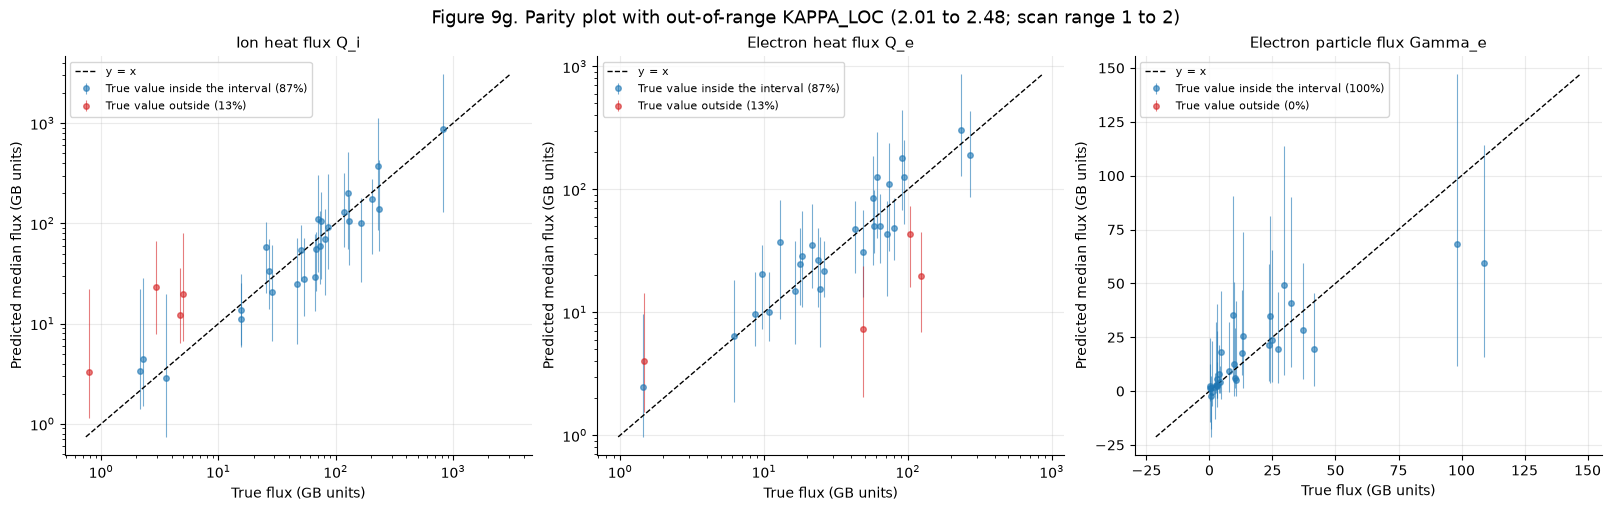

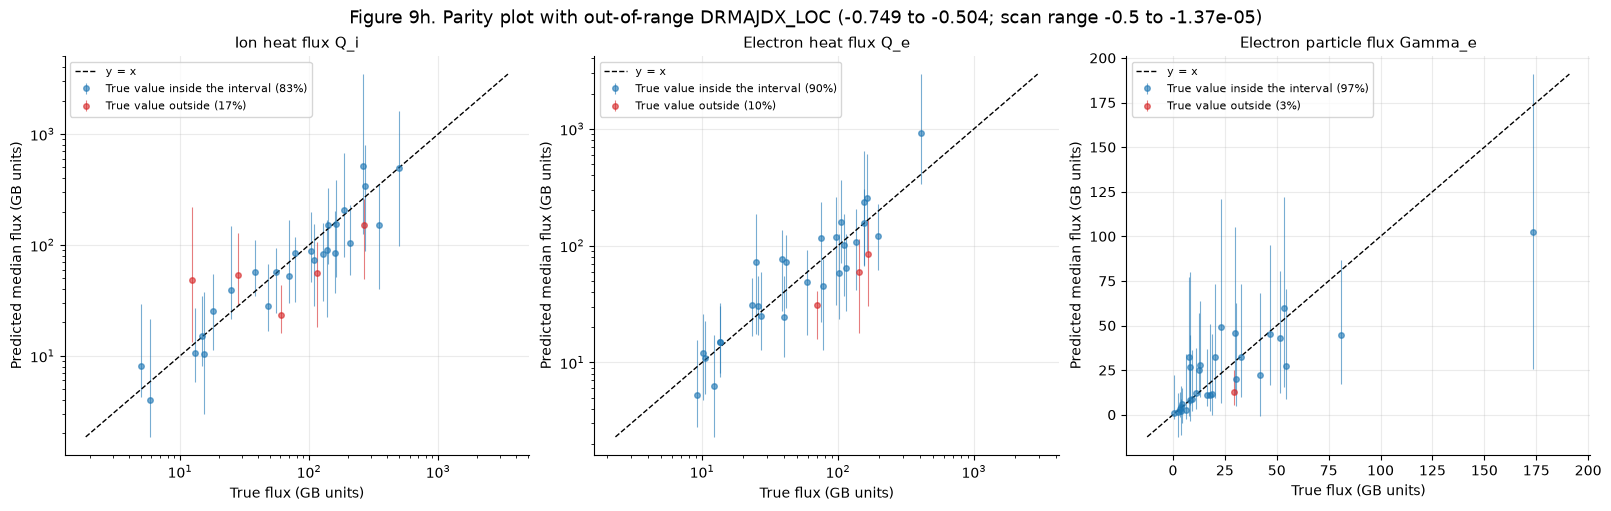

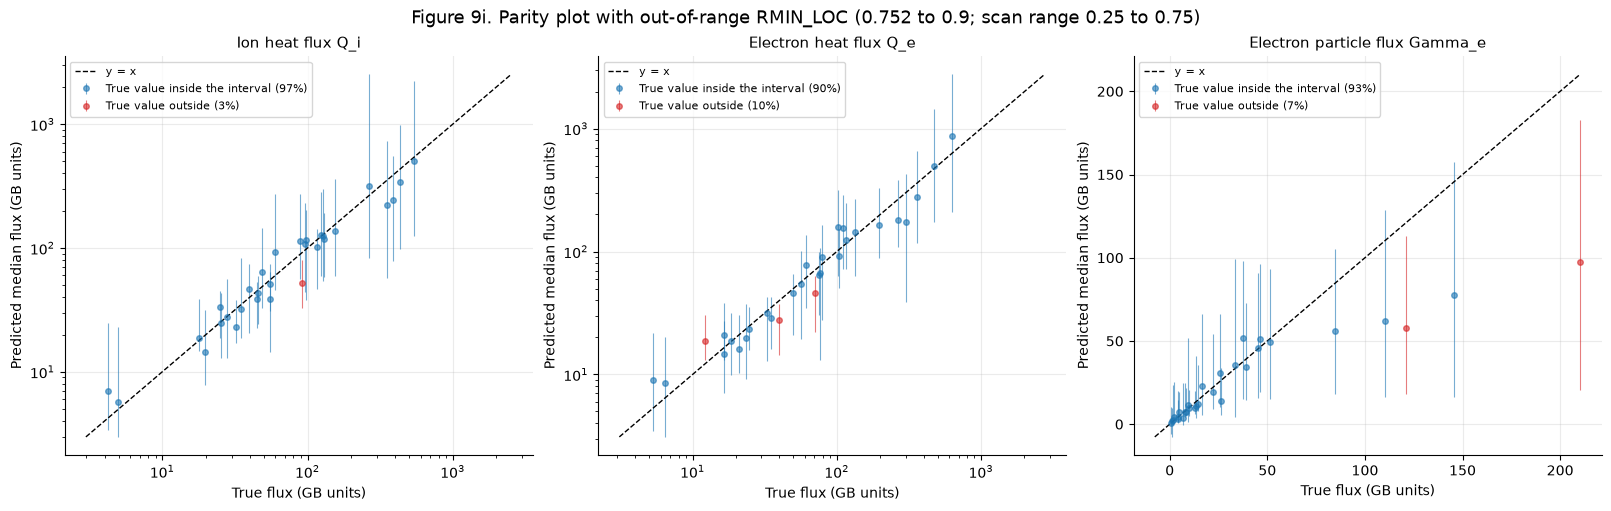

In [138]:
# Figures 9a to 9i: parity plot for each out-of-range table. True value against the predicted median, with the 5-95% interval as a vertical bar.
# Blue = the true value is inside the interval, red = outside.

def draw_parity(ax, t, bands, y_true):
    lower, median, upper = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
    true = y_true[:, t]
    inside = (true >= lower) & (true <= upper)
    for mask, color, label in [(inside, "tab:blue", f"True value inside the interval ({inside.mean():.0%})"),
                               (~inside, "tab:red", f"True value outside ({1 - inside.mean():.0%})")]:
        ax.errorbar(true[mask], median[mask], yerr=[(median - lower)[mask], (upper - median)[mask]], fmt="o", ms=4, color=color,
                    ecolor=color, elinewidth=0.8, alpha=0.6, label=label)
    lims = [min(true.min(), lower.min()), max(true.max(), upper.max())]
    ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="y = x")
    if LOG_FLUX_AXIS[t]:
        ax.set(xscale="log", yscale="log")
    ax.set(xlabel="True flux (GB units)", ylabel="Predicted median flux (GB units)", title=TARGET_NAMES[t])
    ax.legend(loc="upper left")

for letter, (name, s) in zip("abcdefghi", OOD_SETS.items()):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for t, ax in enumerate(axes):
        draw_parity(ax, t, s["bands"], s["y_true"])
    low, high = s["scan_range"]
    fig.suptitle(fig_title("9" + letter, f"Parity plot with out-of-range {s['param']} ({s['value'].min():.3g} to {s['value'].max():.3g}; scan range {low:.3g} to {high:.3g})"))
    plt.show()

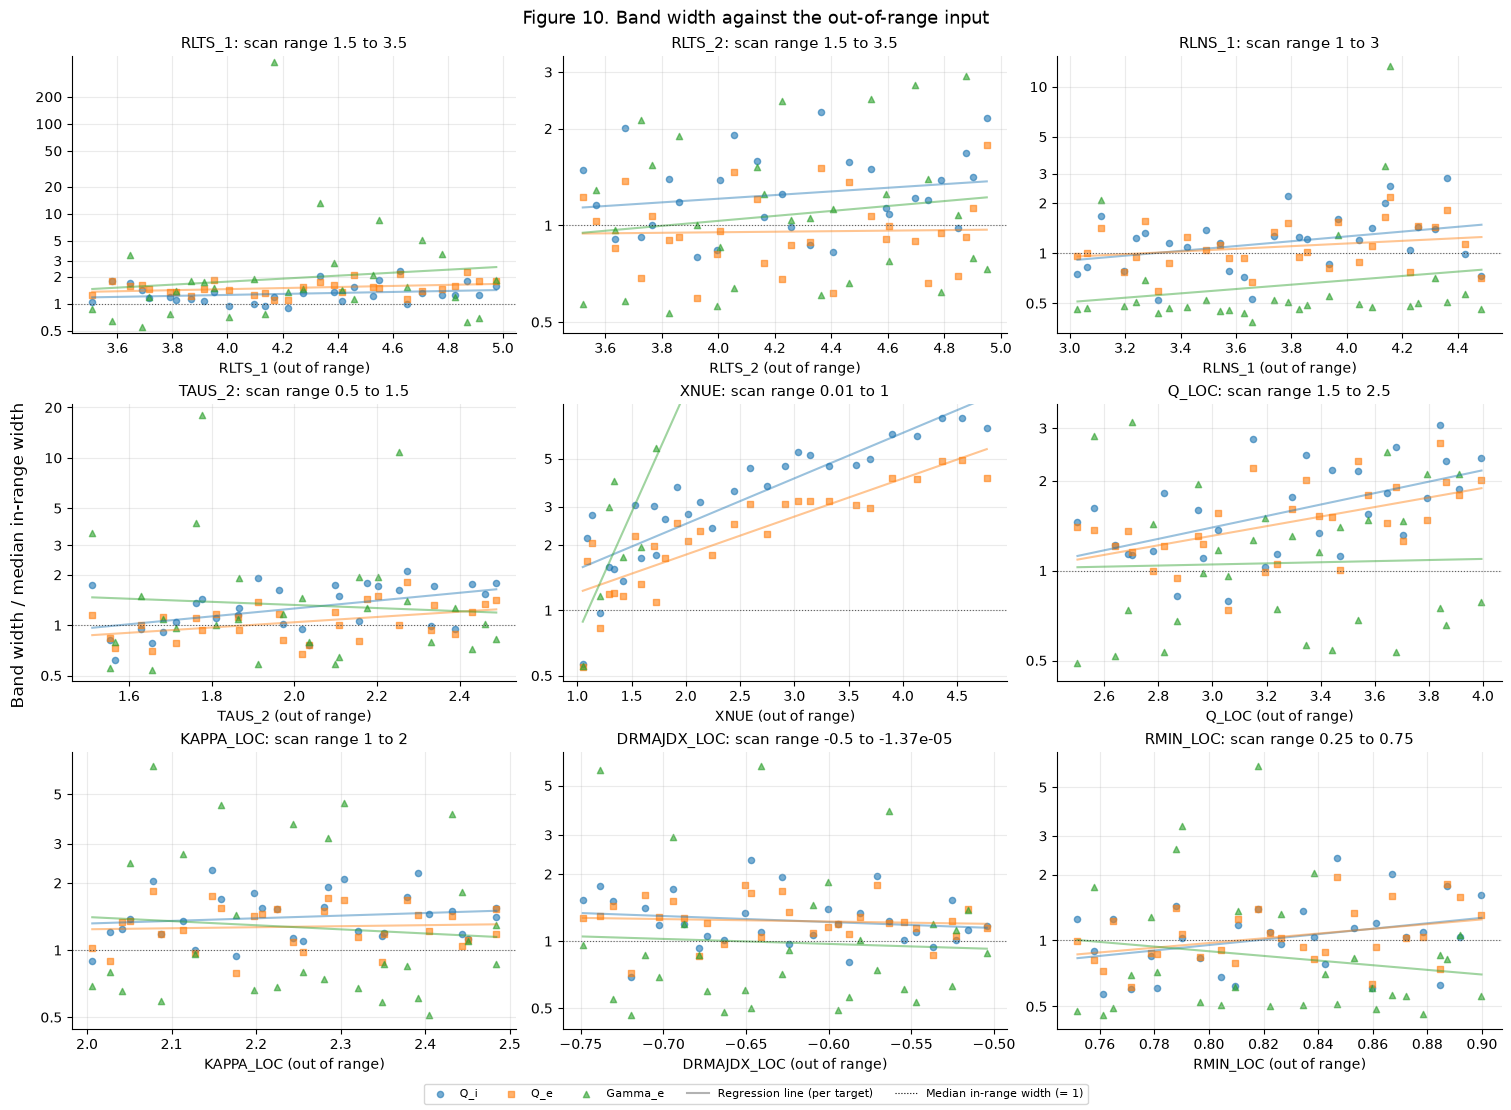

Table 4. Spearman correlation between the distance beyond the scan range and the relative band width


,Q_i,Q_e,Gamma_e
RLTS_1,0.26,0.29,0.24
RLTS_2,0.21,0.03,0.16
RLNS_1,0.32,0.24,0.28
TAUS_2,0.49,0.45,-0.00
XNUE,0.93,0.91,0.71
Q_LOC,0.52,0.57,0.12
KAPPA_LOC,0.13,0.04,-0.01
DRMAJDX_LOC,0.20,0.21,-0.09
RMIN_LOC,0.34,0.38,-0.02


In [141]:
# Figure 10: band width against the out-of-range input, one panel per table, one colour per target.
# The width is the relative band width of Section 6, divided by the median width of that target on the in-range test set (1 = as wide as usual).
# The light line of each target is a least-squares fit of log10(normalized width) on the input value, so it is a straight line on the log axis.
# The y-axis of each panel is fitted to the points (a steep fit line may leave the panel).
# Table 4: Spearman correlation between the distance beyond the edge of the scan range and that normalized width.

from matplotlib.ticker import NullLocator

in_range_width = [np.nanmedian(band_width(SPLITS["test"]["bands"], t, relative=True)[0]) for t in range(3)]

fig, axes = plt.subplots(3, 3, figsize=(15, 11), constrained_layout=True)
correlations_ood = {}
for ax, (name, s) in zip(axes.flat, OOD_SETS.items()):
    low, high = s["scan_range"]
    edge = high if s["value"].mean() > high else low                                      # the edge of the scan range that the values lie beyond
    distance = np.abs(s["value"] - edge)
    correlations_ood[s["param"]] = {}
    shown = []
    for t in range(3):
        width, ok = band_width(s["bands"], t, relative=True)
        normalized = width / in_range_width[t]
        shown.append(normalized[ok])
        ax.scatter(s["value"][ok], normalized[ok], s=20, alpha=0.6, color=TARGET_COLORS[t], marker=TARGET_MARKERS[t], label=TARGET_KEYS[t])
        correlations_ood[s["param"]][TARGET_KEYS[t]] = pd.Series(distance[ok]).corr(pd.Series(normalized[ok]), method="spearman")
        slope, intercept = np.polyfit(s["value"][ok], np.log10(normalized[ok]), 1)
        xs = np.linspace(s["value"].min(), s["value"].max(), 100)
        ax.plot(xs, 10 ** (intercept + slope * xs), color=TARGET_COLORS[t], linewidth=1.5, alpha=0.45)
    ax.axhline(1, color="black", linestyle=":", linewidth=0.8, alpha=0.6)
    shown = np.concatenate(shown)
    bottom, top = shown.min() / 1.15, shown.max() * 1.15
    ax.set(yscale="log", ylim=(bottom, top), xlabel=f"{s['param']} (out of range)", title=f"{s['param']}: scan range {round(low, 2) + 0.0:g} to {round(high, 2) + 0.0:g}")   # rounded for the title; + 0.0 turns -0 into 0
    ticks = [v for v in (0.3, 0.5, 1, 2, 3, 5, 10, 20, 50, 100, 200) if bottom <= v <= top]
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{v:g}" for v in ticks])                                          # plain numbers instead of powers of ten
    ax.yaxis.set_minor_locator(NullLocator())

handles, labels = axes.flat[0].get_legend_handles_labels()
handles += [plt.Line2D([], [], color="gray", linewidth=1.5, alpha=0.6), plt.Line2D([], [], color="black", linestyle=":", linewidth=0.8)]
labels += ["Regression line (per target)", "Median in-range width (= 1)"]
fig.legend(handles, labels, loc="outside lower center", ncol=5)
fig.supylabel("Band width / median in-range width")
fig.suptitle(fig_title(10, "Band width against the out-of-range input"))
plt.show()

print("Table 4. Spearman correlation between the distance beyond the scan range and the relative band width")
table_4 = pd.DataFrame(correlations_ood).T.round(2)
table_4

## 8. DIII-D reference case: input uncertainty

Measured plasma inputs are never exact. For a real DIII-D plasma at r/a = 0.5 (converted to the inputs of the `scan_db` database, all other TGLF settings as in `scan_db`), each input has an error bar. This section asks how much uncertainty that puts on the predicted fluxes. Answering it with TGLF itself takes many runs; the surrogate answers in a single batch.

The data are in `data_d3d/`:

- `d3d_db/tglf_sat2/`: the reference case. TGLF gives $Q_e = 3.63$, $Q_i = 4.31$ and $\Gamma_e = 0.387$.
- `d3d_uq/`: 300 TGLF runs (`u001` to `u300`) with the inputs sampled within the error bars (`samples.csv` lists the sampled values).

| Input | Reference value | Error bar |
|---|---|---|
| RLTS_1 | 2.560 | ±10% |
| RLTS_2 | 1.934 | ±10% |
| RLNS_1 = RLNS_2 | 1.179 | ±10% (kept equal) |
| TAUS_2 | 0.796 | ±10% |
| XNUE | 0.0899 | ±20% |
| Q_LOC | 1.722 | ±5% |
| Q_PRIME_LOC | 4.606 | ±10% |
| KAPPA_LOC | 1.299 | fixed |
| DRMAJDX_LOC | −0.0836 | fixed |
| RMIN_LOC | 0.500 | fixed |
| MASS_2 | 1.0 (D) | fixed |

### 8.1 Reading the data

Both folders were read with `tglf_dataset.py` into `data/d3d_ref_table.csv` (1 run) and `data/d3d_uq_table.csv` (300 runs), the same way as the other tables:

```
python tglf_dataset.py data_d3d/d3d_db data/d3d_ref_table.csv --run-subdir ""
python tglf_dataset.py data_d3d/d3d_uq/data data/d3d_uq_table.csv
```

The reference case has no `data/<case>` level above its `tglf_sat2` folder, hence `--run-subdir ""`.
The cell below passes both tables through the same preprocessing as the training data (the function `prepare_ood` of Section 7) and checks them against the description above. **Table 5** compares each input with its error bar, and **Table 6** gives the spread of the 300 TGLF fluxes, which is the answer the surrogate will have to reproduce.

In [142]:
# read the DIII-D tables and prepare them for the model (same preprocessing as the training data, nothing refit)

D3D_ERROR_BARS = {"RLTS_1": 0.10, "RLTS_2": 0.10, "RLNS_1": 0.10, "TAUS_2": 0.10, "XNUE": 0.20, "Q_LOC": 0.05, "Q_PRIME_LOC": 0.10}   # relative error bars; RLNS_2 is kept equal to RLNS_1
D3D_FIXED = ["KAPPA_LOC", "DRMAJDX_LOC", "RMIN_LOC", "MASS_2"]
D3D_INPUTS = ["RLTS_1", "RLTS_2", "RLNS_1", "RLNS_2", "TAUS_2", "XNUE", "Q_LOC", "Q_PRIME_LOC", *D3D_FIXED]

d3d = {}
for key, table_name, expected_runs in [("reference", "d3d_ref", 1), ("samples", "d3d_uq", 300)]:
    table, X_scaled, y = prepare_ood(table_name)
    assert len(table) == expected_runs, f"{table_name}: expected {expected_runs} runs, found {len(table)}"
    d3d[key] = {"table": table, "X_scaled": X_scaled, "y_true": y.values}      # y_true: TGLF fluxes in the order Q_i, Q_e, Gamma_e

reference = d3d["reference"]["table"].iloc[0]
samples = d3d["samples"]["table"]

# checks against the description: the TGLF reference fluxes, RLNS_1 = RLNS_2 in every run, and each sampled input inside its error bar
assert np.allclose(d3d["reference"]["y_true"][0], [4.31, 3.63, 0.387], rtol=2e-3), "the reference fluxes differ from the description"
assert np.allclose(samples["RLNS_1"], samples["RLNS_2"]), "RLNS_1 and RLNS_2 differ in some run"

rows = []
for name in D3D_INPUTS:
    bar = D3D_ERROR_BARS.get("RLNS_1" if name == "RLNS_2" else name, 0.0)
    value = reference[name]
    tolerance = 1e-6 * abs(value)
    rows.append({
        "input": name, "reference": value, "error bar": f"±{bar:.0%}" if bar else "fixed",
        "sampled min": samples[name].min(), "sampled max": samples[name].max(),
        "inside the error bar": bool(samples[name].between(value * (1 - bar) - tolerance, value * (1 + bar) + tolerance).all()),
        "inside the scan range": bool(samples[name].between(df[name].min(), df[name].max()).all()),
    })
table_5 = pd.DataFrame(rows).set_index("input")
assert table_5["inside the error bar"].all(), "some sampled input lies outside its error bar"

print("Table 5. Reference value, error bar and sampled range of every input (300 runs)")
table_5.round(4)

Table 5. Reference value, error bar and sampled range of every input (300 runs)


,reference,error bar,sampled min,sampled max,inside the error bar,inside the scan range
input,,,,,,
RLTS_1,2.5596,±10%,2.3096,2.8151,True,True
RLTS_2,1.9338,±10%,1.7415,2.1259,True,True
RLNS_1,1.1787,±10%,1.0617,1.2959,True,True
RLNS_2,1.1787,±10%,1.0617,1.2959,True,True
TAUS_2,0.7958,±10%,0.7164,0.8753,True,True
XNUE,0.0899,±20%,0.0721,0.1077,True,True
Q_LOC,1.7216,±5%,1.6361,1.8070,True,True
Q_PRIME_LOC,4.6041,±10%,4.1485,5.0578,True,True
KAPPA_LOC,1.2988,fixed,1.2988,1.2988,True,True


In [143]:
# Table 6: TGLF fluxes at the reference inputs and their spread over the 300 sampled runs
tglf_reference = d3d["reference"]["y_true"][0]
tglf_samples = d3d["samples"]["y_true"]

table_6 = pd.DataFrame({
    "TGLF reference": tglf_reference,
    "mean": tglf_samples.mean(axis=0),
    "std": tglf_samples.std(axis=0, ddof=1),
    "std / mean": tglf_samples.std(axis=0, ddof=1) / tglf_samples.mean(axis=0),
    "min": tglf_samples.min(axis=0),
    "max": tglf_samples.max(axis=0),
}, index=TARGET_KEYS)

print("Table 6. TGLF fluxes (GB units) at the reference inputs and over the 300 runs within the error bars")
table_6.round(3)

Table 6. TGLF fluxes (GB units) at the reference inputs and over the 300 runs within the error bars


,TGLF reference,mean,std,std / mean,min,max
Q_i,4.309,4.436,1.120,0.252,2.094,7.408
Q_e,3.630,4.120,1.105,0.268,1.990,7.669
Gamma_e,0.387,0.483,0.236,0.488,0.053,1.039


### 8.2 The surrogate's flux distribution

The surrogate replaces TGLF in the same experiment: many random input sets, one prediction for each, and the spread of the predictions.

1. **Draw 10,000 input sets.** Every uncertain input is drawn uniformly within its error bar around the reference value (for example RLTS_2 between 1.741 and 2.127), RLNS_2 is kept equal to RLNS_1, and the four fixed inputs stay fixed. The random seed is fixed.
2. **Predict all of them** with the trained ensemble, in one batch. The predicted flux is the **median** output of the ensemble. The spread shown is therefore the effect of the input uncertainty only; the model's own 5-95% interval is a separate uncertainty and is not included here.
3. **Compare with TGLF.** **Figure 11** draws the distribution of the predicted fluxes (blue curve) and that of the 300 TGLF runs (red curve, with a tick for each run). The dashed line is the TGLF flux at the reference inputs. **Table 7** gives the mean and spread of both.
4. **Check the response itself.** **Figure 12** runs the surrogate on the 300 *same* input sets that TGLF used and plots each prediction against its TGLF result. A distribution can only match if the surrogate responds to the inputs the way TGLF does.

In [148]:
# draw many random input sets within the error bars and predict them with the ensemble

N_DRAWS = 10000
rng = np.random.default_rng(RANDOM_STATE)

def draw_inputs(n):
    """n input sets: every uncertain input uniform within its error bar around the reference, RLNS_2 = RLNS_1, the others fixed."""
    values = {}
    for name in D3D_INPUTS:
        if name == "RLNS_2":
            values[name] = values["RLNS_1"]                                       # kept equal to RLNS_1
            continue
        bar = D3D_ERROR_BARS.get(name, 0.0)                                       # 0 for the fixed inputs
        values[name] = reference[name] * (1 + bar * rng.uniform(-1, 1, n))
    return pd.DataFrame(values)

def scale_for_model(inputs):
    """The 11 features the model was trained on, in the training order, scaled with the training-set scaler."""
    X = inputs[list(train_X_df.columns)].copy()
    continuous = list(scaler.feature_names_in_)
    X[continuous] = scaler.transform(X[continuous])
    return X

def predicted_median(X_scaled):
    bands, _, _ = predict_ensemble(ensemble, X_scaled)
    return bands[:, :, 1]                                                        # the median output: (cases, 3 targets) in flux units

draws = draw_inputs(N_DRAWS)
surrogate_draws = predicted_median(scale_for_model(draws))                         # the 10,000 random input sets
surrogate_same_inputs = predicted_median(d3d["samples"]["X_scaled"])               # the 300 input sets that TGLF was run on
surrogate_reference = predicted_median(d3d["reference"]["X_scaled"])[0]            # the reference inputs

In [149]:
# Table 7: mean and spread of the surrogate (10,000 random input sets) and of TGLF (300 runs)
# the last column answers "what flux uncertainty does the input uncertainty cause?": half of the 5-95% range as a percentage of the mean,
# the flux counterpart of an input error bar such as +-10%

def summarize(values):
    low, median, high = (np.percentile(values, q, axis=0) for q in (5, 50, 95))
    return pd.DataFrame({
        "mean": values.mean(axis=0), "std": values.std(axis=0, ddof=1), "std / mean": values.std(axis=0, ddof=1) / values.mean(axis=0),
        "5%": low, "50%": median, "95%": high,
        "uncertainty (+- % of mean)": 100 * (high - low) / 2 / values.mean(axis=0),
    }, index=TARGET_KEYS)

table_7 = pd.concat({
    "TGLF (300 runs)": summarize(tglf_samples).assign(**{"reference inputs": tglf_reference}),
    "Surrogate (10,000 draws)": summarize(surrogate_draws).assign(**{"reference inputs": surrogate_reference}),
}, names=["source", "target"])
table_7 = table_7[["reference inputs", "mean", "std", "std / mean", "5%", "50%", "95%", "uncertainty (+- % of mean)"]]

print("Table 7. Fluxes (GB units) under the input uncertainty; the first column is the flux at the reference inputs")
table_7.round(3)

Table 7. Fluxes (GB units) under the input uncertainty; the first column is the flux at the reference inputs


reference inputs   mean    std  std / mean  \
source                   target                                                
TGLF (300 runs)          Q_i                 4.309  4.436  1.120       0.252   
                         Q_e                 3.630  4.120  1.105       0.268   
                         Gamma_e             0.387  0.483  0.236       0.488   
Surrogate (10,000 draws) Q_i                 6.222  6.362  1.051       0.165   
                         Q_e                 6.257  6.331  0.756       0.119   
                         Gamma_e             0.730  0.756  0.385       0.509   

                                     5%    50%    95%  \
source                   target                         
TGLF (300 runs)          Q_i      2.610  4.358  6.361   
                         Q_e      2.478  3.965  6.172   
                         Gamma_e  0.136  0.472  0.908   
Surrogate (10,000 draws) Q_i      4.821  6.272  8.230   
                         Q_e      5.182  6.284  7.701   
                         Gamma_e  0.155  0.753  1.365   

                                  uncertainty (+- % of mean)  
source                   target                               
TGLF (300 runs)          Q_i                          42.286  
                         Q_e                          44.830  
                         Gamma_e                      79.971  
Surrogate (10,000 draws) Q_i                          26.793  
                         Q_e                          19.897  
                         Gamma_e                      80.077

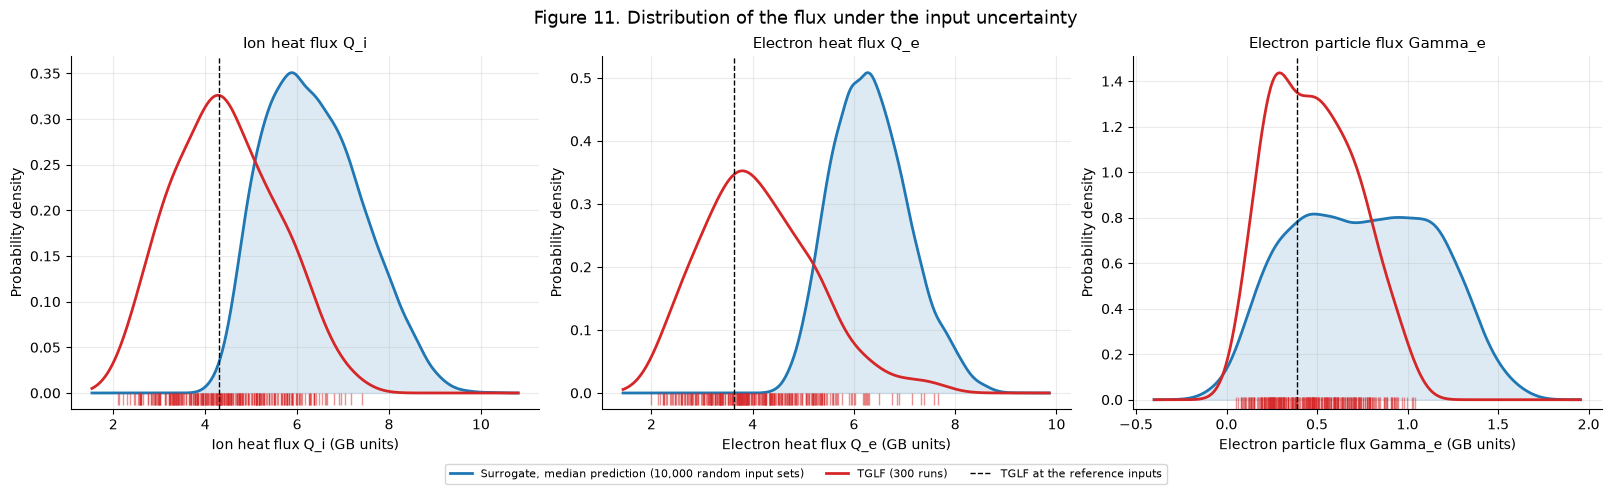

In [146]:
# Figure 11: distribution of the predicted flux (blue) against the distribution of the 300 TGLF runs (red)

def kde_curve(values, grid):
    """Gaussian kernel density estimate of values on grid (Silverman bandwidth)."""
    values = np.asarray(values, dtype=float)
    h = 1.06 * values.std(ddof=1) * len(values) ** (-1 / 5)
    z = (grid[:, None] - values[None, :]) / h
    return np.exp(-0.5 * z ** 2).sum(axis=1) / (len(values) * h * np.sqrt(2 * np.pi))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for t, ax in enumerate(axes):
    predicted, actual = surrogate_draws[:, t], tglf_samples[:, t]
    pad = 0.5 * max(predicted.std(), actual.std())
    grid = np.linspace(min(predicted.min(), actual.min()) - pad, max(predicted.max(), actual.max()) + pad, 400)
    curve = kde_curve(predicted, grid)
    ax.plot(grid, curve, color="tab:blue", linewidth=2, label=f"Surrogate, median prediction ({N_DRAWS:,} random input sets)")
    ax.fill_between(grid, curve, color="tab:blue", alpha=0.15)
    ax.plot(grid, kde_curve(actual, grid), color="tab:red", linewidth=2, label="TGLF (300 runs)")
    ax.plot(actual, np.full(len(actual), -0.02 * curve.max()), "|", color="tab:red", alpha=0.5, markersize=8)     # one tick per TGLF run
    ax.axvline(tglf_reference[t], color="black", linestyle="--", linewidth=1, label="TGLF at the reference inputs")
    ax.set(xlabel=f"{TARGET_NAMES[t]} (GB units)", ylabel="Probability density", title=TARGET_NAMES[t])
    ax.set_ylim(bottom=-0.05 * curve.max())
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)                  # one legend below the panels, so it does not cover the curves
fig.suptitle(fig_title(11, "Distribution of the flux under the input uncertainty"))
plt.show()

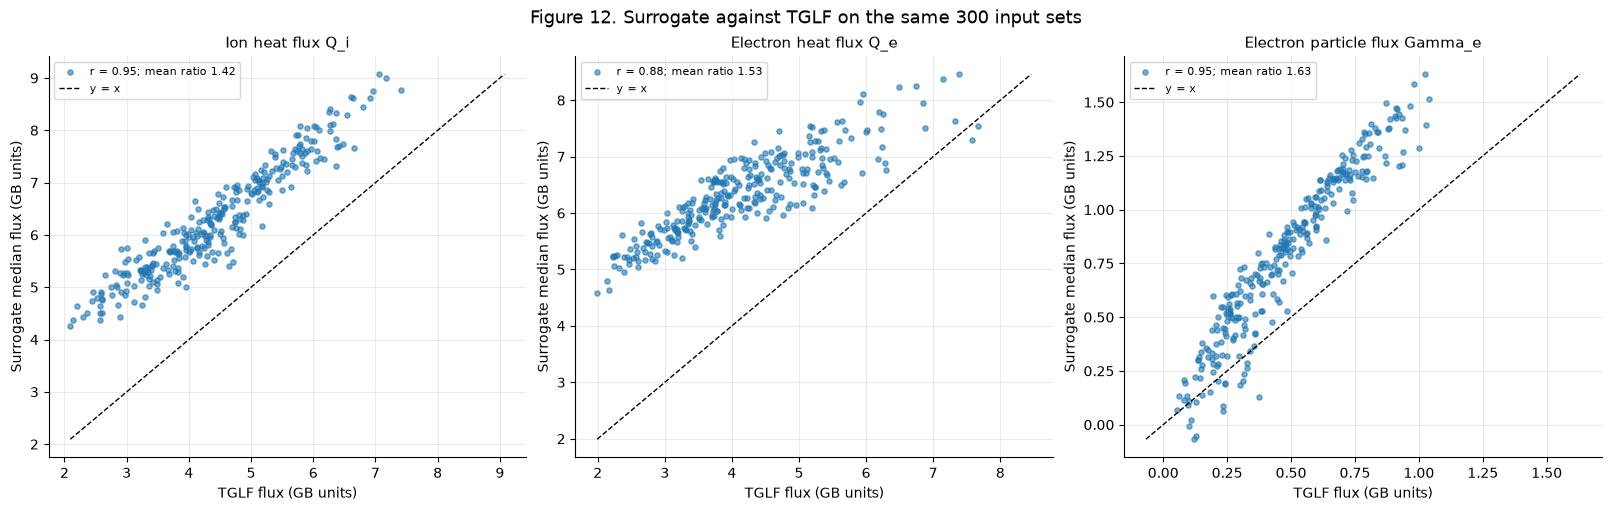

In [147]:
# Figure 12: the surrogate and TGLF on the same 300 input sets, run by run

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for t, ax in enumerate(axes):
    true, predicted = tglf_samples[:, t], surrogate_same_inputs[:, t]
    r = np.corrcoef(true, predicted)[0, 1]                       # how well the surrogate follows TGLF from run to run, whatever the offset
    ax.scatter(true, predicted, s=14, alpha=0.6, color="tab:blue", label=f"r = {r:.2f}; mean ratio {predicted.mean() / true.mean():.2f}")
    lims = [min(true.min(), predicted.min()), max(true.max(), predicted.max())]
    ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="y = x")
    ax.set(xlabel="TGLF flux (GB units)", ylabel="Surrogate median flux (GB units)", title=TARGET_NAMES[t])
    ax.legend(loc="upper left")
fig.suptitle(fig_title(12, "Surrogate against TGLF on the same 300 input sets"))
plt.show()

### 8.3 Where the DIII-D case sits in the training scan

The surrogate is only as good as the training data around the point it is asked about. **Figure 13** compares, for each of the 11 model inputs, the distribution of the values in the training scan (grey) with the 300 values used in the TGLF uncertainty runs (red). The dashed line is the reference case, and its percentile within the training scan is in the panel title.

- The 300 values cover only a narrow band, so their histogram is scaled to the same height as the training histogram. Compare the positions and widths, not the heights.
- An input that is fixed in the DIII-D runs (KAPPA_LOC, DRMAJDX_LOC, RMIN_LOC, MASS_2) has a single value, shown as a red line.
- XNUE and Q_PRIME_LOC span orders of magnitude in the scan, so their axes are logarithmic. MASS_2 takes three values in the scan, so it is shown as bars.

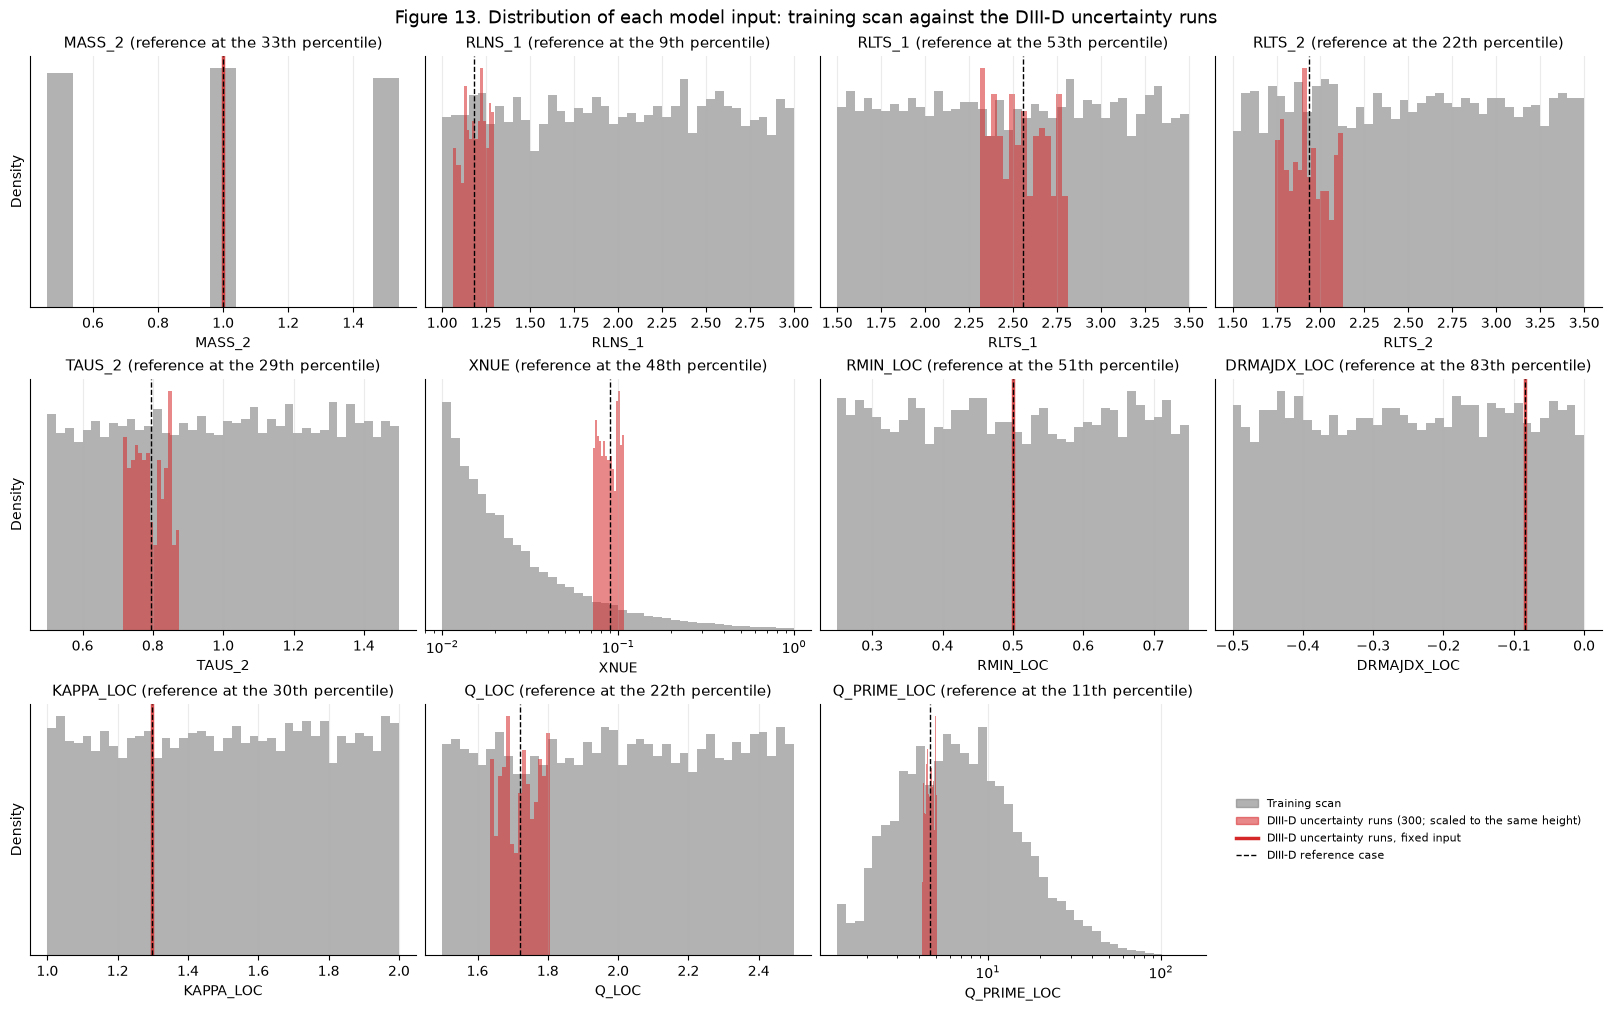

In [150]:
# Figure 13: distribution of every model input in the training scan (grey) against the 300 DIII-D uncertainty runs (red)

LOG_INPUTS = ["XNUE", "Q_PRIME_LOC"]                  # span orders of magnitude in the scan
features = list(train_X_df.columns)                   # the 11 model inputs, in raw (unscaled) units
d3d_inputs = d3d["samples"]["table"]                  # the 300 TGLF runs within the error bars
BINS_SCAN, BINS_D3D = 40, 15

fig, axes = plt.subplots(3, 4, figsize=(16, 10), constrained_layout=True)
for ax, name in zip(axes.flat, features):
    scan_values, d3d_values = train_X_df[name].to_numpy(), d3d_inputs[name].to_numpy()
    ref_value = reference[name]
    percentile = 100 * (scan_values < ref_value).mean()                             # where the reference case sits in the training scan
    if len(np.unique(scan_values)) <= 5:                                           # discrete input (MASS_2): bars at each value
        levels, counts = np.unique(scan_values, return_counts=True)
        ax.bar(levels, counts / counts.sum(), width=0.08, color="tab:gray", alpha=0.6)
    else:
        log = name in LOG_INPUTS
        edges = np.geomspace(scan_values.min(), scan_values.max(), BINS_SCAN + 1) if log else np.linspace(scan_values.min(), scan_values.max(), BINS_SCAN + 1)
        density = np.histogram(scan_values, bins=edges, density=True)[0]
        ax.stairs(density, edges, fill=True, color="tab:gray", alpha=0.6)
        if log:
            ax.set_xscale("log")
    if np.unique(d3d_values).size == 1:                                            # fixed input: a single value
        ax.axvline(d3d_values[0], color="tab:red", linewidth=2.5, alpha=0.8)
    else:
        log = name in LOG_INPUTS
        edges = np.geomspace(d3d_values.min(), d3d_values.max(), BINS_D3D + 1) if log else np.linspace(d3d_values.min(), d3d_values.max(), BINS_D3D + 1)
        heights = np.histogram(d3d_values, bins=edges, density=True)[0]
        ax.stairs(heights / heights.max() * ax.get_ylim()[1], edges, fill=True, color="tab:red", alpha=0.55)    # scaled to the height of the training histogram
    ax.axvline(ref_value, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel=name, ylabel="Density" if name in (features[0], features[4], features[8]) else "", yticks=[], title=f"{name} (reference at the {percentile:.0f}th percentile)")

for ax in axes.flat[len(features):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color="tab:gray", alpha=0.6), plt.Rectangle((0, 0), 1, 1, color="tab:red", alpha=0.55),
           plt.Line2D([], [], color="tab:red", linewidth=2.5), plt.Line2D([], [], color="black", linestyle="--", linewidth=1)]
labels = ["Training scan", "DIII-D uncertainty runs (300; scaled to the same height)", "DIII-D uncertainty runs, fixed input", "DIII-D reference case"]
axes.flat[len(features)].legend(handles, labels, loc="center", frameon=False)
axes.flat[len(features)].axis("off")
fig.suptitle(fig_title(13, "Distribution of each model input: training scan against the DIII-D uncertainty runs"))
plt.show()

### 8.5 How much flux uncertainty does an input uncertainty cause?

Two questions, both answered with the surrogate (TGLF would need a new batch of runs for each):

1. **Every uncertain input at the same error bar of ±10% (Table 8).** What flux uncertainty does a 10% input uncertainty cause?
2. **One input at a time (Table 9, Figure 15).** Only one input gets its error bar and all the others stay at the reference value, so the flux uncertainty shows which input matters most. Each input is run twice: with its **actual** error bar (±10%, except XNUE ±20% and Q_LOC ±5%), and with **±10%** for every input, which compares the inputs' intrinsic sensitivity on equal terms.

**Measure.** The flux uncertainty is half of the 5-95% range of the predicted flux, as a percentage of its mean. This is the flux counterpart of an input error bar. A uniform draw within ±10% has a 5-95% range of ±9%, so that is the input uncertainty on the same measure, and the **amplification** is the flux uncertainty divided by it.
Every scenario uses the same random numbers (the same seed), so the scenarios differ only in their error bars.

**TGLF cross-check.** The surrogate is biased at this reference point (Table 7), so its ranking of the inputs needs checking. TGLF has only the joint runs, so the individual effects are estimated from a straight-line fit of the 300 TGLF fluxes on the seven sampled inputs; the effect of each input is its fitted coefficient times its 5-95% half-range. This is approximate, and the R² of the fit tells how much of the flux variation a straight line explains.

In [152]:
# flux uncertainty for a given set of input error bars

EQUAL_BAR = 0.10

def flux_uncertainty(values):
    """Half of the 5-95% range of each flux as a percentage of its mean: the flux counterpart of an input error bar."""
    low, high = np.percentile(values, [5, 95], axis=0)
    return 100 * (high - low) / 2 / values.mean(axis=0)

def run_scenario(bars, n=N_DRAWS):
    """Input sets and surrogate median fluxes when only the inputs in `bars` vary, each uniform within its relative error bar.
    The same random numbers are used for every scenario, so scenarios differ only in their error bars."""
    scenario_rng = np.random.default_rng(RANDOM_STATE)
    values = {}
    for name in D3D_INPUTS:
        if name == "RLNS_2":
            values[name] = values["RLNS_1"]                                       # kept equal to RLNS_1
            continue
        values[name] = reference[name] * (1 + bars.get(name, 0.0) * scenario_rng.uniform(-1, 1, n))
    inputs = pd.DataFrame(values)
    return inputs, predicted_median(scale_for_model(inputs))

# Table 8: every uncertain input at +-10%
inputs_equal, fluxes_equal = run_scenario({name: EQUAL_BAR for name in D3D_ERROR_BARS})
low, high = np.percentile(inputs_equal["RLTS_1"], [5, 95])
input_uncertainty = 100 * (high - low) / 2 / inputs_equal["RLTS_1"].mean()                  # about 9%: the 5-95% half-range of a uniform +-10% draw

table_8 = pd.DataFrame({
    "input uncertainty (+- %)": input_uncertainty,
    "mean": fluxes_equal.mean(axis=0), "std": fluxes_equal.std(axis=0, ddof=1),
    "5%": np.percentile(fluxes_equal, 5, axis=0), "95%": np.percentile(fluxes_equal, 95, axis=0),
    "flux uncertainty (+- % of mean)": flux_uncertainty(fluxes_equal),
}, index=TARGET_KEYS)
table_8["amplification (flux / input)"] = table_8["flux uncertainty (+- % of mean)"] / input_uncertainty

print("Table 8. Surrogate fluxes (GB units) when every uncertain input has an error bar of +-10%")
table_8.round(2)

Table 8. Surrogate fluxes (GB units) when every uncertain input has an error bar of +-10%


,input uncertainty (+- %),mean,std,5%,95%,flux uncertainty (+- % of mean),amplification (flux / input)
Q_i,9.01,6.34,1.03,4.81,8.17,26.51,2.94
Q_e,9.01,6.31,0.76,5.14,7.65,19.88,2.21
Gamma_e,9.01,0.74,0.40,0.10,1.40,87.62,9.72


In [153]:
# Table 9 and Figure 15: one input at a time

labels = {name: (f"RLNS_1 = RLNS_2 (+-{bar:.0%})" if name == "RLNS_1" else f"{name} (+-{bar:.0%})") for name, bar in D3D_ERROR_BARS.items()}

actual = pd.DataFrame({labels[name]: flux_uncertainty(run_scenario({name: bar})[1]) for name, bar in D3D_ERROR_BARS.items()}, index=TARGET_KEYS).T
equal = pd.DataFrame({labels[name]: flux_uncertainty(run_scenario({name: EQUAL_BAR})[1]) for name in D3D_ERROR_BARS}, index=TARGET_KEYS).T

# TGLF cross-check: straight-line fit of the 300 TGLF fluxes on the seven sampled inputs; effect of an input = |coefficient| x its 5-95% half-range
uncertain = list(D3D_ERROR_BARS)
design = np.column_stack([np.ones(len(samples))] + [samples[name].to_numpy() for name in uncertain])
coefficients = np.linalg.lstsq(design, tglf_samples, rcond=None)[0]                          # (intercept + 7 inputs, 3 fluxes)
fit_r2 = 1 - ((tglf_samples - design @ coefficients) ** 2).sum(axis=0) / ((tglf_samples - tglf_samples.mean(axis=0)) ** 2).sum(axis=0)
tglf_linear = {}
for k, name in enumerate(uncertain):
    p5, p95 = np.percentile(samples[name], [5, 95])
    tglf_linear[labels[name]] = 100 * np.abs(coefficients[k + 1]) * (p95 - p5) / 2 / tglf_samples.mean(axis=0)
tglf_linear = pd.DataFrame(tglf_linear, index=TARGET_KEYS).T

order = actual.mean(axis=1).sort_values(ascending=False).index                               # inputs from the largest to the smallest effect (actual error bars)
table_9 = pd.concat({"Surrogate, actual error bars": actual.loc[order], "TGLF, straight-line fit, actual error bars": tglf_linear.loc[order],
                     "Surrogate, +-10% for every input": equal.loc[order]}, axis=1)
together = np.concatenate([flux_uncertainty(run_scenario(D3D_ERROR_BARS)[1]), flux_uncertainty(tglf_samples), flux_uncertainty(fluxes_equal)])    # in the column order of table_9
table_9 = pd.concat([table_9, pd.DataFrame([together], index=["all inputs together"], columns=table_9.columns)])

print("Table 9. Flux uncertainty (+- % of the mean) when only one input has its error bar. The last row has all the error bars at once (for TGLF: the 300 runs).")
print("R2 of the straight-line fit to the TGLF runs:", dict(zip(TARGET_KEYS, fit_r2.round(2))))
table_9.round(1)

Table 9. Flux uncertainty (+- % of the mean) when only one input has its error bar. The last row has all the error bars at once (for TGLF: the 300 runs).
R2 of the straight-line fit to the TGLF runs: {'Q_i': np.float64(0.91), 'Q_e': np.float64(0.88), 'Gamma_e': np.float64(0.91)}


Surrogate, actual error bars                \
                                                 Q_i   Q_e Gamma_e   
RLNS_1 = RLNS_2 (+-10%)                          5.2  11.8    75.5   
XNUE (+-20%)                                     8.8   8.6    19.7   
RLTS_2 (+-10%)                                  21.0   6.2     7.5   
Q_LOC (+-5%)                                     3.7   4.5    16.4   
TAUS_2 (+-10%)                                  10.1   2.9     6.3   
RLTS_1 (+-10%)                                   1.9   8.2     9.0   
Q_PRIME_LOC (+-10%)                              1.2   0.8     3.2   
all inputs together                             26.8  19.9    80.1   

                        TGLF, straight-line fit, actual error bars        \
                                                               Q_i   Q_e   
RLNS_1 = RLNS_2 (+-10%)                                       10.9  32.9   
XNUE (+-20%)                                                  11.7  15.9   
RLTS_2 (+-10%)                                                31.5   3.7   
Q_LOC (+-5%)                                                   5.9   7.3   
TAUS_2 (+-10%)                                                10.5   0.7   
RLTS_1 (+-10%)                                                 2.6  11.9   
Q_PRIME_LOC (+-10%)                                            3.5   2.9   
all inputs together                                           42.3  44.8   

                                Surrogate, +-10% for every input                
                        Gamma_e                              Q_i   Q_e Gamma_e  
RLNS_1 = RLNS_2 (+-10%)    68.0                              5.2  11.8    75.5  
XNUE (+-20%)               13.8                              4.4   4.3    10.1  
RLTS_2 (+-10%)              8.2                             21.0   6.2     7.5  
Q_LOC (+-5%)               12.2                              7.3   8.9    33.1  
TAUS_2 (+-10%)              0.6                             10.1   2.9     6.3  
RLTS_1 (+-10%)             13.5                              1.9   8.2     9.0  
Q_PRIME_LOC (+-10%)         0.5                              1.2   0.8     3.2  
all inputs together        80.0                             26.5  19.9    87.6

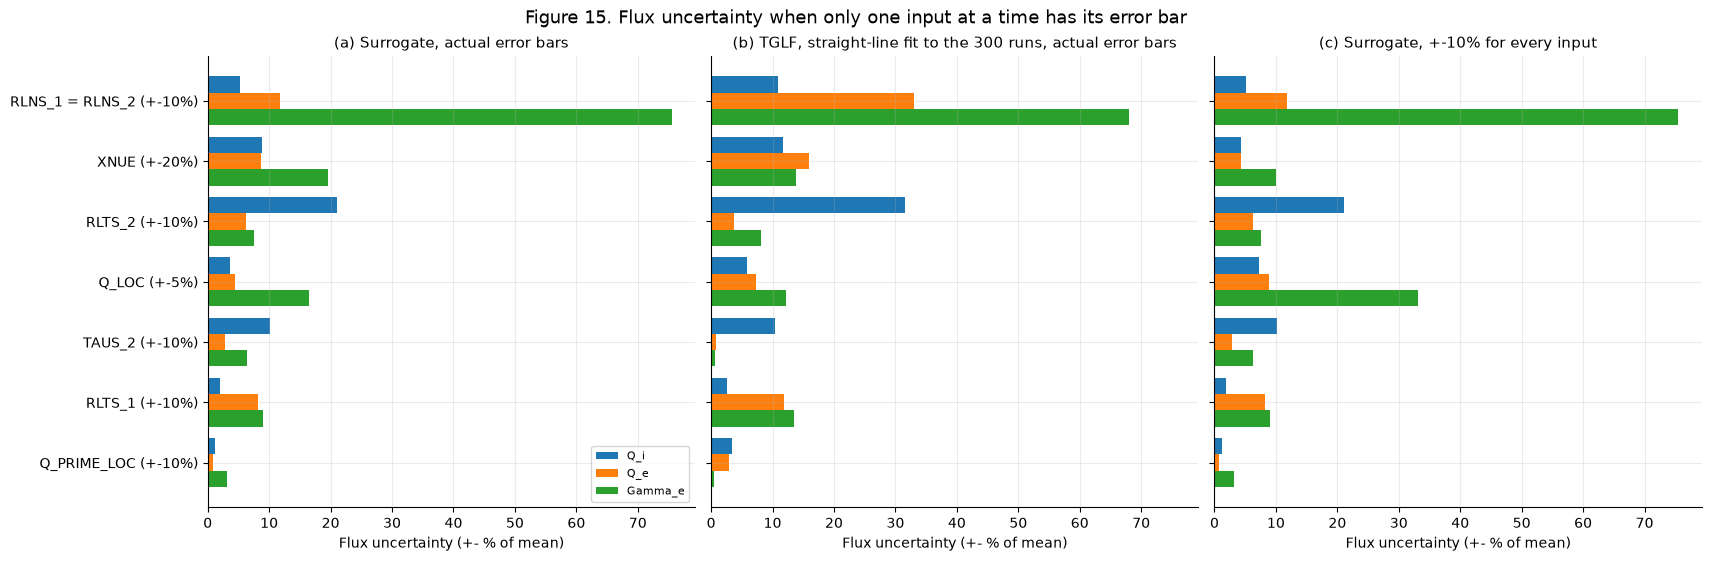

In [154]:
# Figure 15: flux uncertainty from one input at a time (bars: the three fluxes)

panels = [("(a) Surrogate, actual error bars", "Surrogate, actual error bars"),
          ("(b) TGLF, straight-line fit to the 300 runs, actual error bars", "TGLF, straight-line fit, actual error bars"),
          ("(c) Surrogate, +-10% for every input", "Surrogate, +-10% for every input")]
rows = list(order)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True, constrained_layout=True)
for ax, (title, column) in zip(axes, panels):
    positions = np.arange(len(rows))
    for t in range(3):
        ax.barh(positions + (t - 1) * 0.27, table_9.loc[rows, (column, TARGET_KEYS[t])], height=0.27, color=TARGET_COLORS[t], label=TARGET_KEYS[t])
    ax.set(yticks=positions, yticklabels=rows, xlabel="Flux uncertainty (+- % of mean)", title=title)
    ax.invert_yaxis()                                                                       # the largest effect at the top
axes[0].legend()
shared_limit = max(axes[0].get_xlim()[1], axes[1].get_xlim()[1])
axes[0].set_xlim(0, shared_limit)
axes[1].set_xlim(0, shared_limit)                                                           # (a) and (b) on the same scale, to compare them
fig.suptitle(fig_title(15, "Flux uncertainty when only one input at a time has its error bar"))
plt.show()